# Time comparison, Euclid DR1-like 3x2pt: `cloelib` vs `pyccl` vs `CosmoSIS` vs former CLOE, on 8 and 96 CPUs

The DR1 version of `time_comparison_Euclid_DR3.ipynb`. The model, the four codes and the timing protocol are the same. Two things change:
- **6 tomographic bins** from `nz_example.fits`, the DR1-like $n(z)$ that `cloe-org/RunningChains/3x2pt_DR1_like.py` also uses (identical to `she-cal/synthetic_data/nzDR1like.fits`), instead of the 13 SPV3 bins.
- **Two CPU budgets.** This notebook is run twice, pinned with `taskset` (see *Running this notebook* below):
  - **8 CPUs**, a typical laptop;
  - **96 CPUs**: all of NUMA node 1 of `drontermeer` (CPUs 48-95 and 144-191, i.e. 48 cores × 2 hardware threads), the largest budget on that node that runs at full clock. When these runs were made, socket 0 (CPUs 0-47, 96-143) was stuck at 400 MHz, about 9x slower per core. A 128-CPU budget, like the DR3 runs, would have had to include those CPUs. The 8-CPU run uses CPUs 48-55, eight physical cores on the same node.

  Section 4.1 compares the two.

Full photometric 3x2pt ($C_\ell^{\rm gg}$ + $C_\ell^{\rm gE}$ + $C_\ell^{\rm EE}$) with **TATT** intrinsic alignments and **non-linear galaxy bias** (McDonald & Roy 2009 + a $b_{k^2}$ counterterm). Every code computes every bin combination:

$$21\ {\rm GG}\ (i\le j) + 36\ {\rm GE}\ ({\rm all}\ i,j) + 21\ {\rm EE}\ (i\le j) = 78\ \text{spectra}.$$

| | `cloelib` | `pyccl` | `CosmoSIS` (standard library) |
|---|---|---|---|
| galaxy bias | `PositionsTracer(galaxy_bias_model="nonlinear")` + `PBJNonlinearBiasLoopComputer` | `pt.PTNumberCountsTracer` + `EulerianPTCalculator` | `project_2d`: `nlgal-nlgal`, `nlgal-shear` (`pt_type = oneloop_eul_bk`) |
| IA | `ShearTracer(ia_model="TATT")` + `PBJTATTLoopComputer` | `pt.PTIntrinsicAlignmentTracer` | `fast_pt` (`do_ia`) → `tatt` (`ia_model = tatt`) → `shear-intrinsic`, `intrinsic-intrinsic` |
| galaxy–IA term | linear bias only | linear bias only (`_get_pgi`) | `lingal-intrinsic` (linear bias $b_1$) |
| combining the terms | inside one batched Limber call | 177 `angular_cl` calls: GG 21, GE $2\times36$, EE $4\times21$ | `add_intrinsic` |
| matter $P(k)$ | CAMB 1.6.5, Mead2020 | CAMB 1.6.5, Mead2020 (`matter_power_spectrum='camb'`) | CAMB 1.6.5, Mead2020 (`boltzmann/camb`) |

The fourth code, the former **CLOE** likelihood (`github.com/cloe-org/cloe`), runs in its own environment; see section 2.4.

All four use **CAMB Mead2020**.
This is a **timing** comparison. Section 3 checks that the codes produce comparable spectra, not that they agree to validation precision.

**Timing protocol: one full 3x2pt evaluation from scratch.** The quantity measured is what it costs each code to compute all 78 $C_\ell$ for one new parameter point, as a whole.
- **Excluded (computed once, not timed):** the CAMB run that produces the linear and non-linear matter power spectrum and the background.
- **Included (timed):** every step after CAMB, with nothing cached between evaluations.
  - Each code's own background, growth and $P(k,z)$ interpolators built from the CAMB output.
  - Tracers and kernels.
  - All FAST-PT kernels: TATT and non-linear bias.
  - Biased power spectra.
  - The Limber projection of every spectrum.

| code | timed per evaluation | not timed |
|---|---|---|
| cloelib | fresh `PositionsTracer` / `ShearTracer` + loop computers (FAST-PT) + `AngularTwoPoint.get_Cl` ×3. The `CAMBNonLinearPerturbations` interpolators are rebuilt inside every call | `CAMBBackground` / `CAMB*Perturbations` construction (CAMB) |
| pyccl | a new `CosmologyCalculator` from CAMB's $P(k,a)$ arrays (CCL's own background and growth splines), `EulerianPTCalculator` + 5 `Pk2D`, 18 tracers, 177 `angular_cl` | the CAMB-backed `Cosmology` that produced the arrays |
| CosmoSIS | `load_nz` ×2 → `fast_pt` → `tatt` → `project_2d` → `add_intrinsic`, on a fresh copy of the post-CAMB block | `consistency`, `camb` |
| former CLOE | `EuclidLikelihood.logp`: `passing_requirements` (reads CAMB's products from cobaya) → `Cosmology.update_cosmo_dic` (interpolators, FAST-PT TATT and EFT bias loops) → `create_photo_theory` ($C_\ell$); the $\chi^2$ is replaced by a no-op | CAMB through cobaya |

Each value is the **median of `N_REPEAT`** such evaluations at a fixed $\ell$-grid.
The **first call** at each $\ell$-grid is reported separately: it is the same evaluation, but for cloelib it also pays the one-off JAX compilation for that array shape (in a chain this happens once per session). The other codes have no compilation step, so their first call is comparable to the median.

**Environment:** `time_profiling/environment/cloe-cosmosis-env-linux.yaml` + `time_profiling/environment/setup_envs.sh` (kernel `cloe-cosmosis`): the cloelib non-linear-bias branch (PR #596; `tp_paths.CLOELIB['pr596-…']`, see the provenance note above) and CosmoSIS standard library as `validation_cosmosis_nonlinear_bias.ipynb`.

**Running this notebook.** The thread pools of JAX/XLA, OpenMP and BLAS are sized when the process starts, so the CPU budget is fixed for the whole kernel. `run.sh` executes this notebook once per budget, each time with `taskset -c <cpus>` and `OMP/MKL/OPENBLAS_NUM_THREADS = <number of cpus>`:
- 8 CPUs → `time_comparison_Euclid_DR1_8cpu.ipynb`;
- 96 CPUs → this notebook.

Each run writes its section-4 timings to `timings_Euclid_DR1_<N>cpu.json`, and section 4.1 reads all of them, so the 8-CPU run goes first.


> **In cloe-bench.** Executed on `drontermeer` (2026-10-09, 96 CPUs of NUMA node 1) in a working directory outside this repository, then moved here. Since then only path handling has changed: locations come from `time_profiling/tp_paths.py`, results go to `results/` and figures to `figures/`. Local paths in the outputs are shown as `<WORKDIR>`. Set-up and re-running: `time_profiling/README.md`.


## 0. Setup

In [1]:
import os
import sys
import subprocess
import time
import timeit
import warnings

sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))   # time_profiling/, for tp_paths
import tp_paths as tp
RESULTS, FIGURES = os.path.abspath('results'), os.path.abspath('figures')
os.makedirs(FIGURES, exist_ok=True)   # figures are not tracked in git
CLOELIB_BRANCH = str(tp.CLOELIB['pr596-3f443c4'])
CSL_DIR = str(tp.CSL)
INI_DIR = str(tp.INI_WORK)                                  # generated n(z) tables and values files
tp.check(CLOELIB_BRANCH, CSL_DIR, tp.CLOE, tp.PY_CLOE_FORMER, tp.NZ_DR1)
os.environ['CSL_DIR'], os.environ['INI_DIR'] = CSL_DIR, INI_DIR   # used by the .ini files
sys.path.insert(0, CLOELIB_BRANCH)

import cloelib
assert cloelib.__file__.startswith(CLOELIB_BRANCH), f'wrong cloelib imported: {cloelib.__file__}'
_git = lambda repo, *a: subprocess.run(['git', '-C', repo, *a], capture_output=True, text=True).stdout.strip()
print('cloelib  :', _git(CLOELIB_BRANCH, 'rev-parse', '--abbrev-ref', 'HEAD'), '@', _git(CLOELIB_BRANCH, 'rev-parse', '--short', 'HEAD'))
print('CSL      :', _git(CSL_DIR, 'rev-parse', '--abbrev-ref', 'HEAD'), '@', _git(CSL_DIR, 'rev-parse', '--short', 'HEAD'))

cloelib  : 384-implement-nonlinear-galaxy-bias-in-positionstracer @ 3f443c4
CSL      : main @ 9e3dd611


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from scipy import integrate

import euclidlib as el

# cloelib
from cloelib.cosmology.camb_cosmology import CAMBBackground, CAMBLinearPerturbations, CAMBNonLinearPerturbations
from cloelib.observables.photo import ShearTracer, PositionsTracer
from cloelib.observables.photo.shear import PBJTATTLoopComputer
from cloelib.observables.photo.positions import PBJNonlinearBiasLoopComputer
from cloelib.summary_statistics.angular_two_point import AngularTwoPoint

# pyccl
import pyccl as ccl
import pyccl.nl_pt as pt

# CosmoSIS
import cosmosis
from cosmosis import LikelihoodPipeline, Inifile

import camb
import fastpt
import jax
print(f'cosmosis {cosmosis.__version__} | pyccl {ccl.__version__} | fast-pt {fastpt.__version__} | '
      f'camb {camb.__version__} | jax {jax.__version__}')
print(f'CPU cores: {os.cpu_count()} | load average (1/5/15 min): {os.getloadavg()}')
for var in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'XLA_FLAGS'):
    print(f'  {var} = {os.environ.get(var, "not set")}')
CPUS = sorted(os.sched_getaffinity(0))          # CPUs this process may use (taskset)
N_CPU_AVAILABLE = len(CPUS)
THREAD_LABEL = f'{N_CPU_AVAILABLE} CPU' + ('' if N_CPU_AVAILABLE == 1 else 's')
FIG_PREFIX, FIG_SUFFIX = 'time_comparison_Euclid_DR1', f'_{N_CPU_AVAILABLE}cpu'


def cpu_ranges(cpus):
    out = []
    for c in cpus:
        if out and c == out[-1][1] + 1:
            out[-1][1] = c
        else:
            out.append([c, c])
    return ','.join(f'{a}-{b}' if a != b else f'{a}' for a, b in out)


def cpu_mhz(cpus):
    # current clock of each CPU [MHz], where the kernel exposes it
    mhz = {}
    for c in cpus:
        try:
            with open(f'/sys/devices/system/cpu/cpu{c}/cpufreq/scaling_cur_freq') as f:
                mhz[c] = int(f.read()) / 1e3
        except OSError:
            pass
    return mhz


HOST = os.uname().nodename
_mhz = cpu_mhz(CPUS)
print(f'host {HOST} | CPUs available to this process: {N_CPU_AVAILABLE} ({cpu_ranges(CPUS)})  ->  '
      f'results labelled "{THREAD_LABEL}"')
if _mhz:
    print(f'  clock of those CPUs now: min {min(_mhz.values()):.0f} MHz, median {np.median(list(_mhz.values())):.0f} MHz')
    _slow = sorted(c for c, f in _mhz.items() if f < 1000)
    if _slow:   # e.g. a throttled socket: timings on these CPUs are not representative
        warnings.warn(f'{len(_slow)} of the CPUs in use run below 1 GHz: {cpu_ranges(_slow)}')


def code_style_legends(ax, entries, **kw):
    """Two legends: colour/marker -> which code, line style -> from scratch (solid) / first call (dashed)."""
    who = [Line2D([], [], color=col, marker=m, lw=2, label=name) for name, col, m in entries]
    style = [Line2D([], [], color='0.3', lw=2, ls='-', label='from scratch, median (solid)'),
             Line2D([], [], color='0.3', lw=1.2, ls='--', label='first call at this $\\ell$-grid, incl. JIT (dashed)')]
    ax.add_artist(ax.legend(handles=who, loc='upper left', frameon=False, **kw))
    ax.legend(handles=style, loc='lower right', frameon=False, **kw)


sns.set_theme(style="ticks")
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
plt.rc('font', size=14)
plt.rc('axes', labelsize=16)
plt.rc('lines', linewidth=2)
plt.rc('legend', fontsize=12, handlelength=4)  # long enough to show dashed vs solid

CODES = ('cloelib', 'pyccl', 'CosmoSIS', 'CLOE (former)')
# Categorical colours: fixed order (validated: colour-blind safe as adjacent pairs; yellow and aqua are
# below 3:1 contrast, so every chart also carries markers, direct labels and the printed tables)
COL = {'cloelib': '#2a78d6', 'pyccl': '#eb6834', 'CosmoSIS': '#1baf7a', 'CLOE (former)': '#eda100'}
MARK = {'cloelib': 'o', 'pyccl': 's', 'CosmoSIS': 'D', 'CLOE (former)': '^'}
OTHERS = CODES[1:]   # compared against cloelib

# Timing sweep settings (sections 2.4 and 4)
N_REPEAT = 3
nell_values = [32, 100, 500, 1000, 3000]
LOAD_MAX = 16.0      # wait until the 1-min load average is below this before each timing point
LOAD_WAIT_MAX = 900  # ... but for at most this many seconds


def wait_for_quiet(max_load=LOAD_MAX, max_wait=LOAD_WAIT_MAX):
    # Shared machine: start a timing point only when the node is quiet. Returns the load at start.
    t0 = time.time()
    while os.getloadavg()[0] > max_load and time.time() - t0 < max_wait:
        time.sleep(10)
    return os.getloadavg()[0]

cosmosis 3.25.2 | pyccl 3.3.6 | fast-pt 4.1.0 | camb 1.6.5 | jax 0.11.2
CPU cores: 192 | load average (1/5/15 min): (3.26, 3.07, 1.83)
  OMP_NUM_THREADS = 96
  MKL_NUM_THREADS = 96
  OPENBLAS_NUM_THREADS = 96
  XLA_FLAGS = not set
host drontermeer.strw.leidenuniv.nl | CPUs available to this process: 96 (48-95,144-191)  ->  results labelled "96 CPUs"
  clock of those CPUs now: min 2750 MHz, median 2750 MHz


The machine is shared, so the load average above affects the absolute timings.
All codes run with their default threading: JAX/XLA for cloelib, OpenMP in CCL's C layer for pyccl, and the CosmoSIS Limber C library.
The comparison is between ratios measured back to back in the same session.

## 1. Inputs
### 1.1. Redshift distributions: 6 bins from `nz_example.fits`, and the common redshift sampling
`euclidlib` reads the FITS file. Each $n(z)$ is cut at $z\le3$, resampled onto the common grid `zs` (`N_Z` points, uniform in $z$) and renormalised on it.
**Every code receives exactly these arrays**, so the $n(z)$ sampling is identical across codes:
- cloelib and pyccl take `(zs, n_i(zs))` directly.
- CosmoSIS reads `<TP_WORK>/cosmosis_ini/nz_dr1_6bins.txt` (`load_nz`).
- Former CLOE reads `<CLOE>/data/DR1_6bins/Photometric/nzDR1_zs.dat` (the `DR1_6bins` sample is described in section 2.4).
- Both files are written by this cell. Lenses and sources share the same $n(z)$.

`N_Z` also sets the number of points in each code's Limber integral and in its $P(k,z)$ / PT redshift grids (section 2.5).
`N_Z = 100` is the value `time_comparison.ipynb` uses for cloelib.


6 bins | native grid: 1501 points in [0.000, 3.000] | max fraction of n(z) above z=3.0: 0.0e+00
common grid zs: 100 points in [1e-04, 3.0], dz = 0.0303


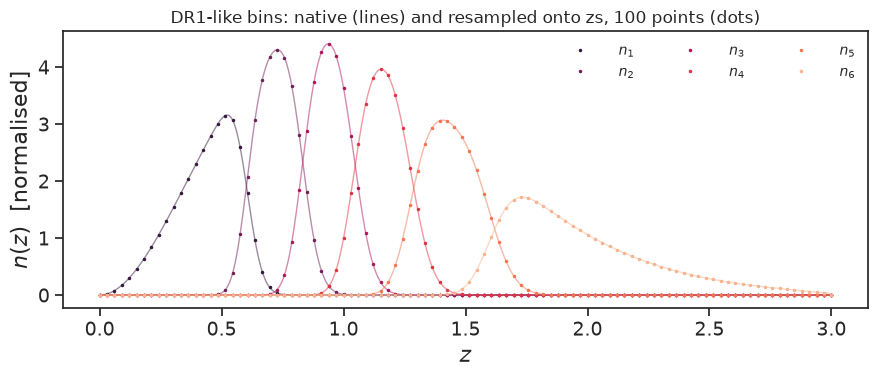

In [3]:
NZ_FILE = str(tp.NZ_DR1)   # Euclid DR1-like, 6 bins
ZMAX = 3.0
N_Z = 100                              # common number of redshift points (Limber + P(k,z)/PT grids)

z_all, nz_all = el.phz.redshift_distributions(NZ_FILE)
sel_z = z_all <= ZMAX
z_nz = z_all[sel_z]
lost = max(1 - integrate.trapezoid(v[sel_z], z_nz) / integrate.trapezoid(v, z_all) for v in nz_all.values())
dndz_native = {k: v[sel_z] / integrate.trapezoid(v[sel_z], z_nz) for k, v in nz_all.items()}
bin_keys = list(dndz_native)
n_bins = len(bin_keys)
n_auto = n_bins * (n_bins + 1) // 2                  # GG and EE pairs (i <= j)
N_SPECTRA = 2 * n_auto + n_bins**2                   # GG + GE (all i, j) + EE
print(f'{n_bins} bins | native grid: {len(z_nz)} points in [{z_nz.min():.3f}, {z_nz.max():.3f}] | '
      f'max fraction of n(z) above z={ZMAX}: {lost:.1e}')

# Common grids
zs = np.linspace(1e-4, ZMAX, N_Z)      # n(z) and Limber sampling (uniform in z)
z_pk = np.linspace(0.0, ZMAX, N_Z)     # P(k, z) / PT redshift grid where a code takes one explicitly
my_dndz_norm = np.vstack([np.interp(zs, z_nz, dndz_native[k]) for k in bin_keys])
my_dndz_norm /= integrate.trapezoid(my_dndz_norm, zs, axis=1)[:, None]
dndz_norm = {k: my_dndz_norm[i] for i, k in enumerate(bin_keys)}   # same arrays, keyed by bin
print(f'common grid zs: {N_Z} points in [{zs[0]:.0e}, {zs[-1]:.1f}], dz = {zs[1] - zs[0]:.4f}')

# CosmoSIS n(z) file
nz_txt = os.path.join(INI_DIR, f'nz_dr1_{n_bins}bins.txt')
np.savetxt(nz_txt, np.column_stack([zs, my_dndz_norm.T]),
           header=f'z n_1 ... n_{n_bins} : nz_example.fits (Euclid DR1-like), cut at z<={ZMAX}, '
                  f'resampled onto linspace(1e-4, {ZMAX}, {N_Z}) and normalised')
# Former CLOE n(z) file (same format as its nzTabSPV3.dat), in its own 6-bin sample directory (section 2.4)
CLOE_SAMPLE = f'DR1_{n_bins}bins'
CLOE_PHOT_DIR = str(tp.cloe_photometric_dir(CLOE_SAMPLE))
os.makedirs(CLOE_PHOT_DIR, exist_ok=True)
NZ_CLOE = 'nzDR1_zs.dat'
np.savetxt(os.path.join(CLOE_PHOT_DIR, NZ_CLOE),
           np.column_stack([zs, my_dndz_norm.T]), delimiter='\t',
           header='z ' + ' '.join(f'n{i + 1}' for i in range(n_bins)))

colors = sns.color_palette("rocket", n_bins)
plt.figure(figsize=(9, 4))
for i, (key, col) in enumerate(zip(dndz_norm, colors)):
    plt.plot(z_nz, dndz_native[key], color=col, lw=1, alpha=0.5)
    plt.plot(zs, dndz_norm[key], color=col, ls='none', marker='.', ms=3, label=f'$n_{{{i+1}}}$')
plt.xlabel(r'$z$')
plt.ylabel(r'$n(z)$  [normalised]')
plt.title(f'DR1-like bins: native (lines) and resampled onto zs, {N_Z} points (dots)')
plt.legend(ncol=3, frameon=False, fontsize=10)
plt.tight_layout()
plt.show()

### 1.2. Cosmology and nuisance parameters
Same cosmology and nuisance values as `time_comparison.ipynb`.
- IA: $A_1=1.72$, $\eta_1=-0.41$, $A_2=0.40$, $\eta_2=2.69$, $b_{\rm TA}=-0.83$, $z_0=0.62$, $C_{\rm IA}=0.0134$.
- Galaxy bias, the same in every bin: $(b_1,b_2,b_s,b_{3\rm nl},b_{k^2}) = (1.0, 0.5, -0.3, 0.2, 0.1)$.

| | `cloelib` | `pyccl` | `CosmoSIS` |
|---|---|---|---|
| TATT amplitudes | `AIA, CIA, EtaIA, A2IA, Eta2IA, bTA, z0IA` | $C_1(z), C_2(z), C_{1\delta}(z)$ built from the same formulas | `A1, alpha1, A2, alpha2, bias_ta, z_piv` (its $C_1$ constant is $\bar\rho_{\rm crit}C_1 = 0.0134$) |
| $k^2$ bias | $b_{k^2}$ [Mpc$^2$], term $\tfrac12 b_{k^2}k^2P_{\rm NL}$ | `bk2`, same convention as cloelib | $b_{kE} = b_{k^2}h^2/2$ [$(h^{-1}{\rm Mpc})^2$] (see `validation_cosmosis_nonlinear_bias.ipynb`) |

In [4]:
COSMO = dict(H0=70.0, Omega_c=0.25, Omega_b=0.05, ns=0.96, As=2e-9, mnu=0.06)
h = COSMO['H0'] / 100

AIA, CIA, EtaIA = 1.72, 0.0134, -0.41
A2IA, Eta2IA, bTA, z0IA = 0.40, 2.69, -0.83, 0.62
b1_gc, b2_gc, bs_gc, b3nl_gc, bk2_gc = 1.0, 0.5, -0.3, 0.2, 0.1

## 2. The four codes
### 2.1. `cloelib`
`CAMBNonLinearPerturbations` (Mead2020) provides the non-linear $P(k)$ and the Limber $k$-grid (`nonlin_pert.k`). The two FAST-PT loop computers take their linear $P(k)$ from a `CAMBLinearPerturbations`.

`CAMBLinearPerturbations.matter_power_spectrum` builds a new `camb.get_matter_power_interpolator(params, ...)` on every call. That re-runs CAMB with its default `kmax=10` and ignores the results computed in `__init__` (see section 1.3 of `validation_cosmosis_nonlinear_bias.ipynb`). `growth_factor` calls it twice, and TATT calls `growth_factor` in every `get_Cl`. With the stock class, every cloelib evaluation would therefore include CAMB runs, which the protocol excludes for every code.

`CachedCAMBLinearPerturbations` fixes this for this notebook only. It builds the interpolator from `self.results` without re-running CAMB, and inherits everything else (`growth_factor`, …), so the loop computers see the same interface. `fresh()` gives a copy with the interpolator rebuilt; `build_cloelib()` calls it, so even this step is redone in every timed evaluation. The cell prints the cost of one stock `growth_factor` call, and the difference between the cached and stock $P_{\rm lin}$. The difference is $\sim10^{-5}$ below $k=5\,{\rm Mpc}^{-1}$. Above that, the stock version extrapolates past `kmax=10`.

In [5]:
def make_background():
    return CAMBBackground(H0=COSMO['H0'], Omega_cdm0=COSMO['Omega_c'], Omega_b0=COSMO['Omega_b'],
                          w0=-1.0, wa=0.0, Omega_k0=0.0, ns=COSMO['ns'], As=COSMO['As'],
                          mnu=COSMO['mnu'], N_mnu=1, gamma_MG=0.545)


class CachedCAMBLinearPerturbations(CAMBLinearPerturbations):
    """CAMBLinearPerturbations whose P_lin(z, k) is interpolated from the CAMB run done in __init__
    (notebook-only workaround, see the markdown above)."""

    def __init__(self, background, redshifts):
        super().__init__(background, redshifts)
        self._build_interp()

    def _build_interp(self):
        self._pk_interp = self.results.get_matter_power_interpolator(
            nonlinear=False, hubble_units=False, k_hunit=False, extrap_kmax=self.kmax,
            var1="delta_tot", var2="delta_tot")

    def fresh(self):
        # New object on the same CAMB run, with its P_lin interpolator rebuilt (timed; no CAMB call)
        new = object.__new__(type(self))
        new.__dict__.update(self.__dict__)
        new._build_interp()
        return new

    def matter_power_spectrum(self, zs, ks, hubble_units=False, k_hunit=False):
        assert not (hubble_units or k_hunit)
        return self._pk_interp.P(zs, ks)


t0 = time.time()
nonlin_pert = CAMBNonLinearPerturbations(make_background(), None, zs, nonlinear_model='mead2020')
lin_pert = CachedCAMBLinearPerturbations(make_background(), zs)
print(f'cloelib cosmology (not timed below): {time.time() - t0:.1f} s | '
      f'{len(nonlin_pert.k)} k-values in [{nonlin_pert.k.min():.1e}, {nonlin_pert.k.max():.1e}] 1/Mpc | '
      f'P(k,z) z-grid: {len(nonlin_pert.z)} (zs + z=0) | Limber grid: zs, {len(zs)} points')

# Common comoving-distance step for the codes that integrate uniformly in chi (pyccl, CosmoSIS):
# N_Z points between chi(zs[0]) and chi(ZMAX), i.e. the same number of points as zs.
CHI_MIN, CHI_MAX = np.asarray(nonlin_pert.background.comoving_distance(np.array([zs[0], ZMAX])), dtype=float)
DCHI = (CHI_MAX - CHI_MIN) / (N_Z - 1)
print(f'common chi step: DCHI = {DCHI:.2f} Mpc  ({N_Z} points over chi = {CHI_MIN:.1f}-{CHI_MAX:.0f} Mpc)')

_stock = CAMBLinearPerturbations(make_background(), zs)
t0 = time.time(); _ = _stock.growth_factor(zs, nonlin_pert.k); t_stock = time.time() - t0
t0 = time.time(); _ = lin_pert.growth_factor(zs, nonlin_pert.k); t_cached = time.time() - t0
_k5 = np.asarray(nonlin_pert.k)[np.asarray(nonlin_pert.k) < 5]
_dp = np.max(np.abs(np.asarray(lin_pert.matter_power_spectrum(zs[::10], _k5))
                    / np.asarray(_stock.matter_power_spectrum(zs[::10], _k5)) - 1))
print(f'growth_factor: stock {t_stock:.3f} s, cached {t_cached * 1e3:.2f} ms | '
      f'max |P_lin cached/stock - 1| for k<5/Mpc: {_dp:.1e}')
del _stock

Note: redshifts have been re-sorted (earliest first)


Note: redshifts have been re-sorted (earliest first)


cloelib cosmology (not timed below): 5.0 s | 211 k-values in [5.0e-05, 5.2e+02] 1/Mpc | P(k,z) z-grid: 100 (zs + z=0) | Limber grid: zs, 100 points
common chi step: DCHI = 64.10 Mpc  (100 points over chi = 0.4-6346 Mpc)
Note: redshifts have been re-sorted (earliest first)


growth_factor: stock 0.003 s, cached 0.40 ms | max |P_lin cached/stock - 1| for k<5/Mpc: 0.0e+00


In [6]:
nuisance_she_tatt = {
    'AIA': AIA, 'CIA': CIA, 'EtaIA': EtaIA, 'A2IA': A2IA, 'bTA': bTA, 'Eta2IA': Eta2IA, 'z0IA': z0IA,
    **{f'multiplicative_bias_{i}': 0.0 for i in range(1, n_bins + 1)},
    **{f'dz_shear_{i}': 0.0 for i in range(1, n_bins + 1)},
    **{f'width_shear_{i}': 1.0 for i in range(1, n_bins + 1)},
}
nuisance_pos_nlbias = {
    **{f'b1_photo_nl_bin{i}': b1_gc for i in range(n_bins)},
    **{f'b2_photo_nl_bin{i}': b2_gc for i in range(n_bins)},
    **{f'bs2_photo_nl_bin{i}': bs_gc for i in range(n_bins)},
    **{f'b3nl_photo_nl_bin{i}': b3nl_gc for i in range(n_bins)},
    **{f'bk2_photo_nl_bin{i}': bk2_gc for i in range(n_bins)},
    **{f'magnification_bias_{i}': 0.0 for i in range(1, n_bins + 1)},
    **{f'dz_pos_{i}': 0.0 for i in range(1, n_bins + 1)},
    **{f'width_pos_{i}': 1.0 for i in range(1, n_bins + 1)},
}


def build_cloelib():
    """Everything after CAMB, from scratch: P_lin interpolator, tracers, fresh FAST-PT loop computers."""
    lin = lin_pert.fresh()
    tr_pos = PositionsTracer(perturbations=nonlin_pert, dndz=my_dndz_norm, z=zs,
                             galaxy_bias_model='nonlinear', nuisance_params=nuisance_pos_nlbias,
                             nl_bias_loop_computer=PBJNonlinearBiasLoopComputer(lin))
    tr_she = ShearTracer(perturbations=nonlin_pert, dndz=my_dndz_norm, z=zs,
                         nuisance_params=nuisance_she_tatt, ia_model='TATT',
                         tatt_loop_computer=PBJTATTLoopComputer(lin))
    return tr_pos, tr_she


def cloelib_3x2pt(tr_pos, tr_she, ells):
    cells = {}
    cells.update(AngularTwoPoint(tr_pos, tr_pos).get_Cl(ells, 0, nonlin_pert.k))
    cells.update(AngularTwoPoint(tr_pos, tr_she).get_Cl(ells, 0, nonlin_pert.k))
    cells.update(AngularTwoPoint(tr_she, tr_she).get_Cl(ells, 0, nonlin_pert.k))
    return cells


_cl = cloelib_3x2pt(*build_cloelib(), np.geomspace(2, 2999, 32))
print(f'cloelib: {len(_cl)} spectra, e.g. keys {list(_cl)[0]}, {list(_cl)[n_auto]}, {list(_cl)[-1]}')

cloelib: 78 spectra, e.g. keys ('POS', 'POS', 1, 1), ('POS', 'SHE', 1, 1), ('SHE', 'SHE', 6, 6)


### 2.2. `pyccl`
`pyccl.Cosmology(matter_power_spectrum='camb')` with Mead2020 and `kmax = 500` runs CAMB once, the same Boltzmann setup as the other codes. Its linear and non-linear $P(k,a)$ arrays are then extracted.
Each timed evaluation builds a **new** `ccl.CosmologyCalculator` from those arrays. This is pyccl's interface for externally supplied power spectra: CCL recomputes its own background and growth splines, but CAMB is not re-run. The cell checks that the spectra are identical to the CAMB-backed cosmology's.
One `EulerianPTCalculator` provides the five biased $P(k,z)$: $P_{gg}$, $P_{g\delta}$, $P_{gI}$, $P_{\delta I}$, $P_{II}$. There is one $(N, G, I)$ tracer triplet per bin, and the triplets are built the same way as in `time_comparison.ipynb`.
FAST-PT $k$-grid: 100 points per decade over cloelib's own $k$ range, the same density `PBJNonlinearBiasLoopComputer` enforces.

**Redshift sampling, matched to `N_Z`** (section 2.5 lists every code's grids):
- **n(z):** tracers get `(zs, n_i(zs))`. The lensing kernels are tabulated on `n_samples = N_Z` points.
- **Limber:** `limber_integration_method='spline'` integrates on a uniform $\chi$ grid with spacing `ccl.spline_params.DCHI_INTEGRATION`. It is set to `DCHI`, i.e. `N_Z` points over $0<z<3$. The default, `qag_quad`, is adaptive and has no fixed number of points.
- **$P(k,a)$:** CCL runs CAMB at, and tabulates on, `get_pk_spline_a()`. `A_SPLINE_NA_PK`, `A_SPLINE_NLOG_PK = 2` and `A_SPLINE_MIN(LOG)_PK` make that `N_Z` scale factors on $0\le z\lesssim3.02$; the one point just past $z=3$ avoids extrapolating at the edge.
- **PT:** `EulerianPTCalculator(a_arr=1/(1+z_pk))`, `N_Z` scale factors.
- These spline parameters must be set before any `Cosmology` is created, because each one copies them.

In [7]:
# Redshift sampling matched to N_Z (see markdown); set before any Cosmology copies them
ccl.spline_params.A_SPLINE_MIN_PK = 1.0 / (1.0 + ZMAX)
ccl.spline_params.A_SPLINE_MINLOG_PK = 0.999 / (1.0 + ZMAX)
ccl.spline_params.A_SPLINE_NLOG_PK = 2
ccl.spline_params.A_SPLINE_NA_PK = N_Z - 1
ccl.spline_params.DCHI_INTEGRATION = DCHI

CCL_PARAMS = dict(h=h, Omega_c=COSMO['Omega_c'], Omega_b=COSMO['Omega_b'], n_s=COSMO['ns'], A_s=COSMO['As'],
                  m_nu=COSMO['mnu'], w0=-1.0, wa=0.0, Omega_k=0.0)

# CAMB through pyccl, once (not timed): only used to produce the P(k, a) arrays
t0 = time.time()
cosmo_camb = ccl.Cosmology(**CCL_PARAMS, transfer_function='boltzmann_camb', matter_power_spectrum='camb',
                           extra_parameters={'camb': {'halofit_version': 'mead2020', 'kmax': 500}})
cosmo_camb.compute_nonlin_power()
_a, _lk, _pk = cosmo_camb.get_linear_power().get_spline_arrays()
PK_LIN = {'a': _a, 'k': np.exp(_lk), 'delta_matter:delta_matter': _pk}
_a, _lk, _pk = cosmo_camb.get_nonlin_power().get_spline_arrays()
PK_NL = {'a': _a, 'k': np.exp(_lk), 'delta_matter:delta_matter': _pk}
print(f'pyccl CAMB run (not timed below): {time.time() - t0:.1f} s | P(k,a) arrays: {len(_a)} a-values '
      f'(z = {1 / _a.max() - 1:.3f}-{1 / _a.min() - 1:.3f}) x {len(_lk)} k-values')


def fresh_ccl_cosmo():
    """A new CCL cosmology from CAMB's P(k,a) arrays: CCL recomputes its own background/growth splines."""
    return ccl.CosmologyCalculator(**CCL_PARAMS, pk_linear=PK_LIN, pk_nonlin=PK_NL)


a_pt = np.sort(1.0 / (1.0 + z_pk))    # PT grid, increasing a
Omega_m0 = COSMO['Omega_c'] + COSMO['Omega_b']
k_cl = np.asarray(nonlin_pert.k)
LOG10K_MIN, LOG10K_MAX, NK_PER_DECADE = np.log10(k_cl.min()), np.log10(k_cl.max()), 100

pairs_auto = [(i, j) for i in range(n_bins) for j in range(i, n_bins)]    # GG and EE
pairs_cross = [(i, j) for i in range(n_bins) for j in range(n_bins)]      # GE
N_CCL_CALLS = len(pairs_auto) + 2 * len(pairs_cross) + 4 * len(pairs_auto)
_one = np.ones_like(zs)


def build_ccl(cosmo):
    """TATT amplitudes, PT calculator + the five biased P(k,z), one (N, G, I) tracer triplet per bin."""
    # C1(z) / C2(z) / C1delta(z), the same formulas as cloelib's TATTContribution
    Dz = cosmo.growth_factor(1.0 / (1.0 + zs))
    C1_z = -AIA * CIA * Omega_m0 * ((1 + zs) / (1 + z0IA)) ** EtaIA / Dz
    C2_z = 5 * A2IA * CIA * Omega_m0 / Dz ** 2 * ((1 + zs) / (1 + z0IA)) ** Eta2IA
    nc = pt.PTNumberCountsTracer(b1=(zs, b1_gc * _one), b2=(zs, b2_gc * _one), bs=(zs, bs_gc * _one),
                                 b3nl=(zs, b3nl_gc * _one), bk2=(zs, bk2_gc * _one))
    ia = pt.PTIntrinsicAlignmentTracer(c1=(zs, C1_z), c2=(zs, C2_z), cdelta=(zs, bTA * C1_z))
    mt = pt.PTMatterTracer()
    ptc = pt.EulerianPTCalculator(with_NC=True, with_IA=True, with_matter_1loop=True, cosmo=cosmo,
                                  log10k_min=LOG10K_MIN, log10k_max=LOG10K_MAX, nk_per_decade=NK_PER_DECADE,
                                  a_arr=a_pt)
    pks = (ptc.get_biased_pk2d(nc, tracer2=nc), ptc.get_biased_pk2d(nc, tracer2=mt),
           ptc.get_biased_pk2d(nc, tracer2=ia), ptc.get_biased_pk2d(mt, tracer2=ia),
           ptc.get_biased_pk2d(ia, tracer2=ia))
    N = [ccl.NumberCountsTracer(cosmo, dndz=(zs, dndz_norm[k]), bias=(zs, _one), has_rsd=False)
         for k in bin_keys]
    G = [ccl.WeakLensingTracer(cosmo, dndz=(zs, dndz_norm[k]), has_shear=True, ia_bias=None,
                               n_samples=N_Z) for k in bin_keys]
    I = [ccl.WeakLensingTracer(cosmo, dndz=(zs, dndz_norm[k]), has_shear=False,
                               ia_bias=(zs, _one), use_A_ia=False, n_samples=N_Z) for k in bin_keys]
    return N, G, I, pks, len(ptc.k_s)


LIMBER = dict(limber_integration_method='spline')   # uniform chi grid, DCHI_INTEGRATION


def ccl_3x2pt(cosmo, N, G, I, pks, ells):
    pk_gg, pk_gG, pk_gI, pk_GI, pk_II = pks
    cls = {}
    for i, j in pairs_auto:
        cls['GG', i, j] = ccl.angular_cl(cosmo, N[i], N[j], ells, p_of_k_a=pk_gg, **LIMBER)
    for i, j in pairs_cross:
        cls['GE', i, j] = (ccl.angular_cl(cosmo, N[i], G[j], ells, p_of_k_a=pk_gG, **LIMBER)
                           + ccl.angular_cl(cosmo, N[i], I[j], ells, p_of_k_a=pk_gI, **LIMBER))
    for i, j in pairs_auto:
        cls['EE', i, j] = (ccl.angular_cl(cosmo, G[i], G[j], ells, **LIMBER)
                           + ccl.angular_cl(cosmo, G[i], I[j], ells, p_of_k_a=pk_GI, **LIMBER)
                           + ccl.angular_cl(cosmo, I[i], G[j], ells, p_of_k_a=pk_GI, **LIMBER)
                           + ccl.angular_cl(cosmo, I[i], I[j], ells, p_of_k_a=pk_II, **LIMBER))
    return cls


def pyccl_from_scratch(ells):
    """One full evaluation after CAMB: new cosmology, PT, tracers, N_CCL_CALLS angular_cl calls."""
    cosmo = fresh_ccl_cosmo()
    return ccl_3x2pt(cosmo, *build_ccl(cosmo)[:4], ells)


cosmo_ccl = fresh_ccl_cosmo()
*_ccl_objs, nk_fpt_ccl = build_ccl(cosmo_ccl)
_cc = ccl_3x2pt(cosmo_ccl, *_ccl_objs, np.geomspace(2, 2999, 32))
_bin_chk = n_bins // 2
_cc_camb = ccl.angular_cl(cosmo_camb, *[ccl.WeakLensingTracer(cosmo_camb, dndz=(zs, dndz_norm[bin_keys[_bin_chk]]),
                                                               n_samples=N_Z)] * 2, np.geomspace(2, 2999, 32), **LIMBER)
_cc_calc = ccl.angular_cl(cosmo_ccl, *[ccl.WeakLensingTracer(cosmo_ccl, dndz=(zs, dndz_norm[bin_keys[_bin_chk]]),
                                                              n_samples=N_Z)] * 2, np.geomspace(2, 2999, 32), **LIMBER)
print(f'pyccl: {len(_cc)} spectra, all finite: {all(np.all(np.isfinite(v)) for v in _cc.values())} | '
      f'FAST-PT grid: {nk_fpt_ccl} points | P(k,a) grid: {len(ccl.pyutils.get_pk_spline_a(cosmo_ccl))} | '
      f'DCHI_INTEGRATION = {cosmo_ccl.cosmo.spline_params.DCHI_INTEGRATION:.2f} Mpc')
print(f'CosmologyCalculator vs CAMB-backed Cosmology, shear bin {_bin_chk + 1}: max |ratio - 1| = '
      f'{np.max(np.abs(_cc_calc / _cc_camb - 1)):.1e}')

pyccl CAMB run (not timed below): 13.1 s | P(k,a) arrays: 100 a-values (z = 0.000-3.004) x 211 k-values


pyccl: 78 spectra, all finite: True | FAST-PT grid: 702 points | P(k,a) grid: 100 | DCHI_INTEGRATION = 64.10 Mpc
CosmologyCalculator vs CAMB-backed Cosmology, shear bin 4: max |ratio - 1| = 0.0e+00


### 2.3. `CosmoSIS`
The pipeline is `benchmarks/cosmosis/pipeline_3x2pt_tatt_nlbias.ini`:

`consistency → camb` (run once, not timed) `→ load_nz_lens → load_nz_source → fast_pt → tatt → project_2d → add_intrinsic` (timed: one evaluation from scratch).

`project_2d` computes six spectrum types: `nlgal-nlgal`, `nlgal-shear`, `lingal-intrinsic`, `shear-shear`, `shear-intrinsic` and `intrinsic-intrinsic`. `add_intrinsic` then sums them into `galaxy_cl`, `galaxy_shear_cl` and `shear_cl`.
- `fast_pt` uses `always_init = T`: the `FASTPT` object is rebuilt on every call, like cloelib's fresh loop computers and pyccl's fresh `EulerianPTCalculator`.
- This cell writes `values_3x2pt_tatt_nlbias_dr1.ini` from the parameters in section 1.2. The pipeline file is shared with the DR3 notebook, so the values file and the two `load_nz` file paths are passed as `Inifile` overrides.
- `project_2d`'s $\ell$-grid is fixed at setup (`n_ell_logspaced`), so each $\ell$-grid gets its own `LikelihoodPipeline`, built with an `Inifile` override.
- Each timed evaluation runs the six modules on a fresh clone of the post-CAMB block (`DataBlock.clone()`), so nothing from a previous evaluation is reused. Running the modules one by one also gives the per-module breakdown.
- CosmoSIS has no cache between pipeline runs: every module recomputes everything, including reading the n(z) files.

**Redshift sampling, matched to `N_Z`:**
- **$P(k,z)$:** CAMB `nz = N_Z` on $0\le z\le3$ (`zmin`, `zmax`, `nz` overrides). `fast_pt` and `tatt` work on this same $z$ grid (FAST-PT at $z=0$, scaled by $D(z)$).
- **n(z) and lensing kernels:** the n(z) comes from `zs`, and the lensing kernel is tabulated with `shear_kernel_dchi = DCHI`.
- **Limber:** `project_2d` integrates each spectrum with the trapezoid rule on a uniform $\chi$ grid, step `dchi = min(sigma_1, sigma_2) / sig_over_dchi`. That step is set per pair from the kernel widths, and no ini option fixes it. `fix_limber_dchi` wraps `Spectrum.compute_limber`, which every spectrum class calls, and passes the common `dchi = DCHI` instead. This is a notebook-only patch, like the cloelib one in 2.1. Each pair is still integrated over the overlap of its two kernels, so a pair uses at most `N_Z` points.

In [8]:
values = ['[cosmological_parameters]', f'h0 = {h}', f'omega_m = {Omega_m0}', f'omega_b = {COSMO["Omega_b"]}',
          'omega_k = 0.0', 'w = -1.0', 'wa = 0.0', f'n_s = {COSMO["ns"]}', f'A_s = {COSMO["As"]}',
          f'mnu = {COSMO["mnu"]}', 'num_massive_neutrinos = 1', 'nnu = 3.044', 'tau = 0.0544', '',
          '[intrinsic_alignment_parameters]', f'A1 = {AIA}', f'alpha1 = {EtaIA}', f'A2 = {A2IA}',
          f'alpha2 = {Eta2IA}', f'bias_ta = {bTA}', f'z_piv = {z0IA}', '',
          '[bias_lens]']
for i in range(1, n_bins + 1):
    values += [f'b1E_bin{i} = {b1_gc}', f'b2E_bin{i} = {b2_gc}', f'bsE_bin{i} = {bs_gc}',
               f'b3nlE_bin{i} = {b3nl_gc}', f'bkE_bin{i} = {bk2_gc * h**2 / 2}',   # Mpc^2 -> (Mpc/h)^2, and the 1/2
               f'b_lin_bin{i} = {b1_gc}']                                           # galaxy-IA term (linear bias)
VALUES_INI = os.path.join(INI_DIR, 'values_3x2pt_tatt_nlbias_dr1.ini')
with open(VALUES_INI, 'w') as f:
    f.write('; written by time_comparison_Euclid_DR1.ipynb\n' + '\n'.join(values) + '\n')

PIPELINE_INI = str(tp.PIPELINE_INI)
CAMB_MODULES = ['consistency', 'camb']                                   # not timed
TIMED_MODULES = ['load_nz_lens', 'load_nz_source', 'fast_pt', 'tatt', 'project_2d', 'add_intrinsic']


CS_LIMBER_POINTS = []   # (chimax - chimin) / dchi + 1 for each Limber call, filled by the patch below


def fix_limber_dchi(pipe, dchi_fixed):
    # project_2d's per-pair Limber step (kernel sigma / sig_over_dchi) -> the common DCHI (see markdown)
    lib = {m.name: m for m in pipe.modules}['project_2d'].library
    orig = getattr(lib.Spectrum.compute_limber, '__wrapped__', lib.Spectrum.compute_limber)

    def compute_limber(self, block, ell, bin1, bin2, dchi=None, sig_over_dchi=100., chimin=None, chimax=None):
        if len(CS_LIMBER_POINTS) < 2000:
            K1 = self.source.kernels[self.sample_a].get_kernel_spline(self.kernel_types[0], bin1)
            K2 = self.source.kernels[self.sample_b].get_kernel_spline(self.kernel_types[1], bin2)
            lo, hi = max(K1.xmin_clipped, K2.xmin_clipped), min(K1.xmax_clipped, K2.xmax_clipped)
            CS_LIMBER_POINTS.append(max(int((hi - lo) / dchi_fixed) + 1, 0))   # 0: kernels do not overlap
        return orig(self, block, ell, bin1, bin2, dchi=dchi_fixed, sig_over_dchi=sig_over_dchi,
                    chimin=chimin, chimax=chimax)

    compute_limber.__wrapped__ = orig
    lib.Spectrum.compute_limber = compute_limber


def make_cosmosis_pipeline(n_ell):
    override = {('pipeline', 'values'): VALUES_INI,
                ('load_nz_lens', 'filepath'): nz_txt, ('load_nz_source', 'filepath'): nz_txt,
                ('project_2d', 'n_ell_logspaced'): str(n_ell),
                ('project_2d', 'shear_kernel_dchi'): str(DCHI),
                ('camb', 'zmin'): '0.0', ('camb', 'zmax'): str(ZMAX), ('camb', 'nz'): str(N_Z)}
    ini = Inifile(PIPELINE_INI, override=override, print_include_messages=False)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        pipe = LikelihoodPipeline(ini)
    fix_limber_dchi(pipe, DCHI)
    return pipe


def run_modules(pipe, names, block):
    mods = {m.name: m for m in pipe.modules}
    for name in names:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')   # FAST-PT 'to_do' deprecation notices
            status = mods[name].execute(block)
        assert status == 0, f'CosmoSIS module {name} failed'
    return block


_pipe32 = make_cosmosis_pipeline(32)
t0 = time.time()
block_cosmo = run_modules(_pipe32, CAMB_MODULES, _pipe32.build_starting_block([]))
print(f'\nCosmoSIS CAMB run (not timed below): {time.time() - t0:.1f} s | P(k,z) z-grid: '
      f'{len(block_cosmo["matter_power_nl", "z"])} points, z = {block_cosmo["matter_power_nl", "z"].min():.2f}-'
      f'{block_cosmo["matter_power_nl", "z"].max():.2f}')

_b = run_modules(_pipe32, TIMED_MODULES, block_cosmo.clone())
n_spec = {sec: sum(1 for s, k in _b.keys() if s == sec and k.startswith('bin_'))
          for sec in ('galaxy_cl', 'galaxy_shear_cl', 'shear_cl')}
print('CosmoSIS spectra:', n_spec, '-> total', sum(n_spec.values()))
print(f'CosmoSIS Limber points per spectrum (dchi = {DCHI:.2f} Mpc): min {min(CS_LIMBER_POINTS)}, '
      f'median {int(np.median(CS_LIMBER_POINTS))}, max {max(CS_LIMBER_POINTS)}  '
      f'({len(CS_LIMBER_POINTS)} Limber calls)')


Setting up module consistency
------------------------------



Setting up module camb
-----------------------



Setting up module load_nz_lens
-------------------------------


Found 6 samples and 100 bins in redshift in file <WORKDIR>/cosmosis_ini/nz_dr1_6bins.txt

Setting up module load_nz_source
---------------------------------


Found 6 samples and 100 bins in redshift in file <WORKDIR>/cosmosis_ini/nz_dr1_6bins.txt

Setting up module fast_pt
--------------------------


...

Calculating Limber: Kernel 1 = ('W', 'source'), Kernel 2 = ('W', 'source'), P_3D = MatterPower3D, section = matter_power_nl --> Output: shear_cl
Calculating Limber: Kernel 1 = ('W', 'source'), Kernel 2 = ('N', 'source'), P_3D = MatterIntrinsicPower3D, section = matter_intrinsic_power --> Output: shear_cl_gi
Calculating Limber: Kernel 1 = ('N', 'source'), Kernel 2 = ('N', 'source'), P_3D = IntrinsicPower3D, section = intrinsic_power --> Output: shear_cl_ii
Calculating Limber: Kernel 1 = ('N', 'lens'), Kernel 2 = ('N', 'source'), P_3D = MatterIntrinsicPower3D, section = matter_intrinsic_power --> Output: galaxy_intrinsic_cl
Calculating Limber: Kernel 1 = ('N', 'lens'), Kernel 2 = ('N', 'lens'), P_3D = MatterPower3D, section = matter_power_nl --> Output: galaxy_cl
Calculating Limber: Kernel 1 = ('N', 'lens'), Kernel 2 = ('W', 'source'), P_3D = MatterPower3D, section = matter_power_nl --> Output: galaxy_shear_cl
Will project these spectra into 2D:
    -  shear_cl
    -  shear_cl_gi
    -  


The add_intrinsic module will try to combine IA terms into these spectra:
 - shear-shear.
 - position-shear.

Setup all pipeline modules




Parameter Priors
----------------
cosmological_parameters--h0                     ~ delta(0.7)
cosmological_parameters--omega_m                ~ delta(0.3)
cosmological_parameters--omega_b                ~ delta(0.05)
cosmological_parameters--omega_k                ~ delta(0.0)
cosmological_parameters--w                      ~ delta(-1.0)
cosmological_parameters--wa                     ~ delta(0.0)
cosmological_parameters--n_s                    ~ delta(0.96)
cosmological_parameters--a_s                    ~ delta(2e-09)
cosmological_parameters--mnu                    ~ delta(0.06)
cosmological_parameters--num_massive_neutrinos  ~ delta(1)
cosmological_parameters--nnu                    ~ delta(3.044)
cosmological_parameters--tau                    ~ delta(0.0544)
intrinsic_alignment_parameters--a1              ~ delta(1.72)
intrinsic_alignment_parameters--alpha1          ~ delta(-0.41)
intrinsic_alignment_parameters--a2              ~ delta(0.4)
intrinsic_alignment_parameters--alpha2


CosmoSIS CAMB run (not timed below): 3.1 s | P(k,z) z-grid: 100 points, z = 0.00-3.00


CosmoSIS spectra: {'galaxy_cl': 21, 'galaxy_shear_cl': 36, 'shear_cl': 21} -> total 78
CosmoSIS Limber points per spectrum (dchi = 64.10 Mpc): min 0, median 14, max 69  (171 Limber calls)


### 2.4. Former CLOE (`github.com/cloe-org/cloe`)
The former CLOE likelihood code (no longer maintained), cloned into `cloe/` (`main`). Its pinned dependencies (Python 3.9, numpy 1.23, `fast-pt` 3.1.1, `camb` 1.5.0, `cobaya` 3.3.1) cannot coexist with `cloe-cosmosis`, so it runs in its own environment, the `cloe-former` environment (`time_profiling/environment/cloe-former-env-linux.yaml`), as a subprocess: `cloe_former_benchmark.py`, which writes its timings to JSON.

- **Model:** `IA_flag = 1` (TATT), `NL_flag_phot_bias = 1` (one-loop photometric galaxy bias), `NL_flag_phot_matter = 3` (Mead2020), magnification off. The cosmology and TATT parameters are the same as above. CLOE's non-linear bias uses the Lagrangian $(b_1, b_2, b_{\mathcal G_2}, b_{\Gamma_3})$ basis; the values are illustrative (the timing does not depend on them), so its GG/GE spectra are **not** expected to match the other codes (section 3).
- **Inputs:** the sample directory `<CLOE>/data/DR1_6bins`. The $n(z)$ is `nzDR1_zs.dat`: the common `zs` arrays of section 1.1, written there by that cell.
  - CLOE's reader builds the masked data vector and loads the 3x2pt covariance at init, and their sizes must match the number of bins, even though the $\chi^2$ is never computed here. `cloe_former_benchmark.py --n-bins 6 --sample DR1_6bins` therefore builds this directory from `SPV3_13bins` (`make_sample`): the 13-bin data vectors restricted to bins 1–6, and a **placeholder identity covariance**. Neither enters the timed theory evaluation.
  - The photometric bin mean redshifts that CLOE takes as input are computed from the same $n(z)$ file.
  - The 10-bin mixing matrix the reader loads at init is never applied (`matrix_transform_phot = False`, no pseudo-$C_\ell$).
- **Redshift sampling, matched to `N_Z`:**
  - **$P(k,z)$ / PT interpolators:** `z_samp = N_Z` on $0\le z\le3$ (CLOE's `z_win`, default $0$–$4$). The TATT and EFT bias loops are computed at $z=0$ and evaluated on this grid.
  - **Limber integral:** `Photo.z_grid_for_cl` is hard-coded to `arange(0.001, 4, 0.01)`, 400 points. The script replaces it with `zs`.
  - **Window-function tables:** `Photo.z_winterp`, hard-coded to 1000 log-spaced points, which the lensing-efficiency integral also runs on. The script replaces it with `zs`.
- **Other grids:** `k_samp = 1000` (log-spaced, $10^{-5}$–$500\,{\rm Mpc}^{-1}$). The $\ell$-grid is patched to `np.geomspace(2, 2999, n_ell)` on all three probes, with the Limber prefactors recomputed, as in `CLOE-NL/time_cloe_1000ells.py`.
- **Timing:** CAMB runs once through cobaya and is not timed. That call also records the exact parameter dict cobaya passes to the likelihood.
  - One evaluation from scratch is `EuclidLikelihood.logp(**params)`. It runs `passing_requirements`, which reads CAMB's products from cobaya, then `Cosmology.update_cosmo_dic`, which rebuilds the interpolators and the FAST-PT TATT and EFT bias loops, then `Euclike.create_photo_theory`, the $C_\ell$.
  - The $\chi^2$ against data is replaced by a no-op, so only the theory is timed.
  - The first call at each $\ell$-grid and the median of `N_REPEAT` calls are recorded, and so is the median of each of the three parts.

In [9]:
import json

checks = [('GG', 0, 0), ('GG', 3, 3), ('GE', 1, 4), ('EE', 0, 0), ('EE', 2, 5), ('EE', 5, 5)]   # section 3 (0-based)
CLOE_ARGS = ['--n-bins', str(n_bins), '--sample', CLOE_SAMPLE, '--checks', ','.join(f'{p}:{i}:{j}' for p, i, j in checks)]
CLOE_PY = str(tp.PY_CLOE_FORMER)
CLOE_JSON = os.path.join(RESULTS, f'cloe_former_DR1_timings{FIG_SUFFIX}.json')
CLOE_NPZ = os.path.join(RESULTS, f'cloe_former_DR1_spectra_nell32{FIG_SUFFIX}.npz')
cmd = [CLOE_PY, str(tp.CLOE_FORMER_BENCHMARK), '--nell', *map(str, nell_values),
       '--repeat', str(N_REPEAT), '--out', CLOE_JSON, '--spectra-out', CLOE_NPZ,
       '--n-z', str(N_Z), '--z-max', str(ZMAX), '--nz-file', NZ_CLOE, *CLOE_ARGS]
env_cloe = {**os.environ, 'TMPDIR': str(tp.TMP), 'PYTHONWARNINGS': 'ignore'}
load_cloe_start = wait_for_quiet()
t0 = time.time()
proc = subprocess.run(cmd, capture_output=True, text=True, env=env_cloe, cwd=str(tp.TP))
load_cloe_end = os.getloadavg()[0]
for line in proc.stdout.splitlines():
    if line.startswith(('CLOE model', 'n_ell=')):
        print(line)
assert proc.returncode == 0, proc.stderr[-3000:]
print(f'[former CLOE subprocess: {time.time() - t0:.0f} s | 1-min load average: start {load_cloe_start:.1f}, '
      f'end {load_cloe_end:.1f}]')

with open(CLOE_JSON) as f:
    cloe_former = json.load(f)
cloe_former_spectra = dict(np.load(CLOE_NPZ))
assert all(n == N_SPECTRA for n in cloe_former['n_spectra'].values())
print(f'former CLOE grids: n(z) file {cloe_former["n_z_nz_file"]} rows | P(k,z) z_win {cloe_former["n_z"]} points '
      f'(z = {cloe_former["z_win_range"][0]:.1f}-{cloe_former["z_win_range"][1]:.1f}) | Limber '
      f'{cloe_former["n_z_limber"]} | window tables {cloe_former["n_z_windows"]} | k_win {cloe_former["n_k"]}')

CLOE model init 3.5 s | first logposterior (incl. CAMB) 2.0 s
n_ell=   32 | CLOE from scratch   1.206s  first call   1.244s  (passing_requirements 0.002s, update_cosmo_dic 1.177s, create_photo_theory 0.025s) 78 spectra
n_ell=  100 | CLOE from scratch   1.249s  first call   1.248s  (passing_requirements 0.002s, update_cosmo_dic 1.178s, create_photo_theory 0.068s) 78 spectra
n_ell=  500 | CLOE from scratch   1.495s  first call   1.494s  (passing_requirements 0.002s, update_cosmo_dic 1.178s, create_photo_theory 0.315s) 78 spectra
n_ell= 1000 | CLOE from scratch   1.809s  first call   1.803s  (passing_requirements 0.002s, update_cosmo_dic 1.177s, create_photo_theory 0.622s) 78 spectra
n_ell= 3000 | CLOE from scratch   3.067s  first call   3.330s  (passing_requirements 0.002s, update_cosmo_dic 1.174s, create_photo_theory 1.882s) 78 spectra
[former CLOE subprocess: 79 s | 1-min load average: start 3.4, end 1.9]
former CLOE grids: n(z) file 100 rows | P(k,z) z_win 100 points (z = 0.0-3.0) | L

### 2.5. Grids: redshift sampling and FAST-PT resolution
**Redshift sampling: matched**, `N_Z` points everywhere (sections 2.1–2.4):

| | n(z) input | Limber integral | $P(k,z)$ / PT redshift grid |
|---|---|---|---|
| `cloelib` | `zs` | `zs`, uniform in $z$ | `zs` + $z=0$ |
| `pyccl` | `zs`; lensing kernels on `n_samples = N_Z` | `spline`, uniform in $\chi$, `DCHI_INTEGRATION = DCHI` | `get_pk_spline_a()`, `N_Z` values; PT `a_arr` from `z_pk` |
| `CosmoSIS` | `zs`; lensing kernels with `shear_kernel_dchi = DCHI` | trapezoid, uniform in $\chi$, `dchi = DCHI` (patched) | CAMB `nz = N_Z` on $0$–$3$ (`fast_pt` and `tatt` use the same grid) |
| former CLOE | `zs` | `z_grid_for_cl = zs` (patched), uniform in $z$ | `z_win`: `z_samp = N_Z` on $0$–$3$; window tables on `zs` (patched) |

cloelib and CLOE sample uniformly in $z$, pyccl and CosmoSIS uniformly in $\chi$, so the number of points matches but the nodes do not.
pyccl and CosmoSIS integrate each pair over the overlap of its two kernels, so a given pair can use fewer than `N_Z` points.
The printed per-spectrum counts show how many.

**FAST-PT $k$-grids: each code's own** (not matched). cloelib, pyccl and CosmoSIS run the same `fast-pt` package with `low_extrap=-5`, `high_extrap=3` and `C_window=0.75`, but each on its own $k$-grid. Former CLOE uses an older `fast-pt` for TATT and its own `FASTPTPlus` for the bias loops:

| | TATT kernels | non-linear bias kernels |
|---|---|---|
| `cloelib` | `len(nonlin_pert.k)` log-uniform points over the same range (~30 per decade with CAMB's $k$-grid) | ≥100 per decade (`_MIN_POINTS_PER_DECADE`) |
| `pyccl` | one shared grid, 100 per decade (set in 2.2) | (same grid) |
| former CLOE | `Misc.ia_tatt_terms`: `fast-pt` 3.1.1 on `k_win` (`k_samp = 1000` log-spaced points over $10^{-5}$–$500\,{\rm Mpc}^{-1}$, ~130 per decade) | `EFTofLSS` (`calculate_phot_nl_bias`): CLOE's own `FASTPTPlus`, 1000 points over $10^{-4}$–$10^{1.7}$ (~175 per decade), `low_extrap=-6`, `high_extrap=5` |
| `CosmoSIS` | `fast_pt`: CAMB's $P_{\rm lin}$ grid upsampled ×4 (`k_res_fac`) | `project_2d`: CAMB's $P_{\rm lin}$ grid upsampled ×4 (`fpt_upsample`), computed separately for `nlgal-nlgal` and `nlgal-shear` |

The cell below prints the actual grid sizes, redshift and $k$. For $k$, each code keeps its default resolution, except pyccl, which has no single default that matches the other two.

In [10]:
_lc_tatt, _lc_nl = PBJTATTLoopComputer(lin_pert), PBJNonlinearBiasLoopComputer(lin_pert)
_lc_tatt._kernels_for(k_cl); _lc_nl._kernels_for(k_cl)
n_k_camb_cs = len(block_cosmo['matter_power_lin', 'k_h'])
_nk = int(4 * n_k_camb_cs); _nk += _nk % 2
print(f'cloelib   TATT kernels: {len(k_cl) + len(k_cl) % 2} points | NL-bias kernels: '
      f'{max(len(k_cl), int(np.ceil(100 * np.log10(k_cl.max() / k_cl.min()))))} points  '
      f'(over {np.log10(k_cl.max() / k_cl.min()):.1f} decades)')
print(f'pyccl     shared grid : {nk_fpt_ccl} points')
print(f'CosmoSIS  fast_pt (TATT): ~{_nk} points | project_2d (NL bias): {4 * n_k_camb_cs} points, '
      f'from CAMB P_lin on {n_k_camb_cs} k-values')
print(f'former CLOE TATT: {cloe_former["n_k"]} points (k_win) | NL bias (EFTofLSS): 1000 points')

print('\nRedshift sampling (N_Z = %d):' % N_Z)
print(f'  cloelib    n(z) {my_dndz_norm.shape[1]} | Limber {len(zs)} | P(k,z) {len(nonlin_pert.z)} (zs + z=0)')
print(f'  pyccl      n(z) {len(zs)} | Limber: DCHI_INTEGRATION {cosmo_ccl.cosmo.spline_params.DCHI_INTEGRATION:.2f} Mpc '
      f'= {int(round((CHI_MAX - CHI_MIN) / cosmo_ccl.cosmo.spline_params.DCHI_INTEGRATION)) + 1} points over 0<z<3 '
      f'| P(k,a) {len(ccl.pyutils.get_pk_spline_a(cosmo_ccl))} | PT {len(a_pt)}')
print(f'  CosmoSIS   n(z) {len(zs)} | Limber: dchi {DCHI:.2f} Mpc, points per spectrum min/median/max '
      f'{min(CS_LIMBER_POINTS)}/{int(np.median(CS_LIMBER_POINTS))}/{max(CS_LIMBER_POINTS)} '
      f'| P(k,z) {len(block_cosmo["matter_power_nl", "z"])}')
print(f'  former CLOE n(z) {cloe_former["n_z_nz_file"]} | Limber {cloe_former["n_z_limber"]} | '
      f'P(k,z) {cloe_former["n_z"]} | window tables {cloe_former["n_z_windows"]}')

cloelib   TATT kernels: 212 points | NL-bias kernels: 703 points  (over 7.0 decades)
pyccl     shared grid : 702 points
CosmoSIS  fast_pt (TATT): ~1600 points | project_2d (NL bias): 1600 points, from CAMB P_lin on 400 k-values
former CLOE TATT: 1000 points (k_win) | NL bias (EFTofLSS): 1000 points

Redshift sampling (N_Z = 100):
  cloelib    n(z) 100 | Limber 100 | P(k,z) 100 (zs + z=0)
  pyccl      n(z) 100 | Limber: DCHI_INTEGRATION 64.10 Mpc = 100 points over 0<z<3 | P(k,a) 100 | PT 100
  CosmoSIS   n(z) 100 | Limber: dchi 64.10 Mpc, points per spectrum min/median/max 0/14/69 | P(k,z) 100
  former CLOE n(z) 100 | Limber 100 | P(k,z) 100 | window tables 100


## 3. Sanity check: the four codes compute comparable spectra
Before timing, check that the codes compute physically comparable spectra. The figure compares a few bin pairs at $n_\ell=32$, relative to CosmoSIS.
The dashed line is cloelib with its $\sigma^4$ kernel set to zero (`NoSig4LoopComputer`, as in `validation_cosmosis_nonlinear_bias.ipynb`), which isolates the first item below.
The codes are **not** expected to agree at validation level here, for these known reasons:
- **$\sigma^4$ convention** in $P_{gg}$. cloelib always subtracts the low-$k$ constants. CosmoSIS never does. pyccl's `EulerianPTCalculator` defaults to `sub_lowk=False`, like CosmoSIS. This mostly affects GG.
- **Spin-2 prefactor.** cloelib applies the exact $\sqrt{(\ell-1)\ell(\ell+1)(\ell+2)}/(\ell+\tfrac12)^2$ factor to GE (and its square to EE). CosmoSIS applies neither. This only matters at low $\ell$.
- **Growth and FAST-PT conventions**: the $k$ at which $D(z)$ is read off, and the FAST-PT grids of section 2.5.
- **Former CLOE's bias basis.** CLOE uses $(b_1, b_2, b_{\mathcal G_2}, b_{\Gamma_3})$ with illustrative values (section 2.4), so its GG and GE are a different model point; only its EE is directly comparable. CLOE also applies the spin-2 prefactor.
- **Limber integrators.** The number of redshift points is matched (`N_Z`), but the nodes are uniform in $z$ for cloelib and CLOE and uniform in $\chi$ for pyccl and CosmoSIS. The quadrature rules and the $P(k,z)$ interpolation also differ. At `N_Z = 100` the narrow low-$z$ bins are sampled coarsely, so part of the remaining scatter is integration error, shared by all codes but not identically.

`validation_cosmosis_nonlinear_bias.ipynb` and `validation_ccl_nonlinear_bias.ipynb` do the precision validation of the bias model.

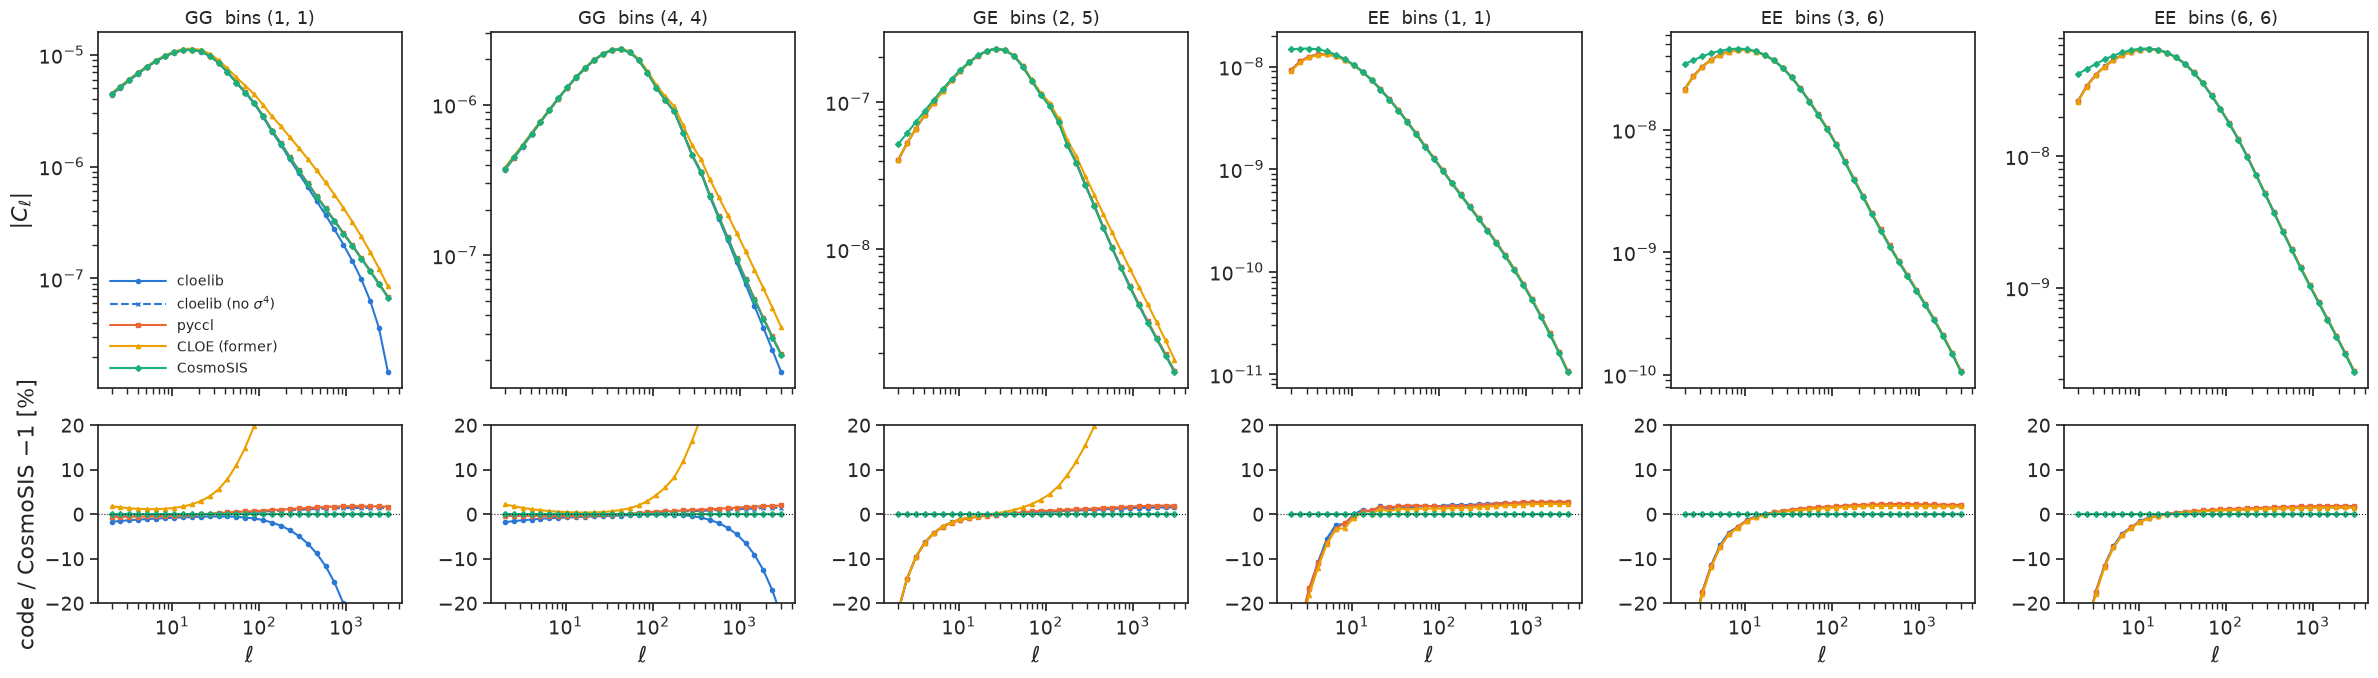

max |code / CosmoSIS - 1| for ell > 20 [%]
  GG ( 1, 1):  cloelib   78.51   cloelib no-sigma^4   1.42   pyccl   1.81   CLOE  73.71
  GG ( 4, 4):  cloelib   22.83   cloelib no-sigma^4   1.46   pyccl   1.96   CLOE  59.79
  GE ( 2, 5):  cloelib    1.55   cloelib no-sigma^4   1.55   pyccl   1.95   CLOE  34.10
  EE ( 1, 1):  cloelib    2.76   cloelib no-sigma^4   2.76   pyccl   2.79   CLOE   2.31
  EE ( 3, 6):  cloelib    2.02   cloelib no-sigma^4   2.02   pyccl   2.29   CLOE   1.88
  EE ( 6, 6):  cloelib    1.56   cloelib no-sigma^4   1.56   pyccl   1.86   CLOE   1.51


In [11]:
import jax.numpy as jnp

ells_chk = np.geomspace(2, 2999, 32)


class NoSig4LoopComputer:
    # Same interface as PBJNonlinearBiasLoopComputer, with the sigma^4 kernel set to zero:
    # the CosmoSIS (and pyccl sub_lowk=False) convention. Same wrapper as in
    # validation_cosmosis_nonlinear_bias.ipynb, section 0.1; used only for this check.
    def __init__(self, inner):
        self.inner = inner

    def compute(self, name):
        f = self.inner.compute(name)
        if name != 'nlbias_sig4':
            return f
        return lambda matter_pk, ks, zs: jnp.zeros_like(f(matter_pk, ks, zs))


_tr_pos_nos4 = PositionsTracer(perturbations=nonlin_pert, dndz=my_dndz_norm, z=zs,
                               galaxy_bias_model='nonlinear', nuisance_params=nuisance_pos_nlbias,
                               nl_bias_loop_computer=NoSig4LoopComputer(PBJNonlinearBiasLoopComputer(lin_pert)))
_cl_nos4 = cloelib_3x2pt(_tr_pos_nos4, build_cloelib()[1], ells_chk)
CHECK_CODES = ('cloelib', 'cloelib (no sigma^4)', 'pyccl', 'CLOE (former)', 'CosmoSIS')
COL_CHK = {**COL, 'cloelib (no sigma^4)': COL['cloelib']}
MARK_CHK = {**MARK, 'cloelib (no sigma^4)': 'x'}
LS_CHK = {'cloelib (no sigma^4)': '--'}
ell_cs = _b['shear_cl', 'ell']
assert np.allclose(ell_cs, ells_chk)


def get_spectrum(code, probe, i, j):
    """probe in GG/GE/EE, 0-based bins i, j (GE: i = lens, j = source)."""
    if code.startswith('cloelib'):
        a, b = {'GG': ('POS', 'POS'), 'GE': ('POS', 'SHE'), 'EE': ('SHE', 'SHE')}[probe]
        arr = np.asarray((_cl_nos4 if 'sigma' in code else _cl)[a, b, i + 1, j + 1].array)
        # spin-2 components: GE is (E, B), EE is ((EE, EB), (BE, BB)) -> keep the E-mode part
        return arr if probe == 'GG' else arr[0] if probe == 'GE' else arr[0, 0]
    if code == 'pyccl':
        return _cc[probe, i, j]
    if code == 'CLOE (former)':
        return cloe_former_spectra[f'{probe}_{i}_{j}']
    sec = {'GG': 'galaxy_cl', 'GE': 'galaxy_shear_cl', 'EE': 'shear_cl'}[probe]
    key = f'bin_{i + 1}_{j + 1}'
    if probe != 'GE' and not _b.has_value(sec, key):
        key = f'bin_{j + 1}_{i + 1}'
    return _b[sec, key]


# `checks`: the six bin pairs defined in section 2.4 (former CLOE saves the same ones)
fig, axs = plt.subplots(2, len(checks), figsize=(4 * len(checks), 7), sharex=True,
                        gridspec_kw={'height_ratios': [2, 1]})
max_dev = {}
for col, (probe, i, j) in enumerate(checks):
    ref = get_spectrum('CosmoSIS', probe, i, j)
    for code in CHECK_CODES:
        c = get_spectrum(code, probe, i, j)
        sty = dict(color=COL_CHK[code], marker=MARK_CHK[code], ms=3, lw=1.5, ls=LS_CHK.get(code, '-'))
        axs[0, col].loglog(ells_chk, np.abs(c), label=code.replace('sigma^4', r'$\sigma^4$'), **sty)
        axs[1, col].semilogx(ells_chk, (c / ref - 1) * 100, **sty)
        m = ells_chk > 20
        max_dev[code, probe, i, j] = np.max(np.abs(c[m] / ref[m] - 1)) * 100
    axs[0, col].set_title(f'{probe}  bins ({i + 1}, {j + 1})', fontsize=13)
    axs[1, col].axhline(0, color='k', lw=0.8, ls=':')
    axs[1, col].set_ylim(-20, 20)
    axs[1, col].set_xlabel(r'$\ell$')
axs[0, 0].set_ylabel(r'$|C_\ell|$')
axs[1, 0].set_ylabel(r'code / CosmoSIS $-1$ [%]')
axs[0, 0].legend(frameon=False, fontsize=10)
fig.tight_layout()
plt.show()

print('max |code / CosmoSIS - 1| for ell > 20 [%]')
for probe, i, j in checks:
    print(f'  {probe} ({i + 1:2d},{j + 1:2d}):  cloelib {max_dev["cloelib", probe, i, j]:7.2f}   '
          f'cloelib no-sigma^4 {max_dev["cloelib (no sigma^4)", probe, i, j]:6.2f}   '
          f'pyccl {max_dev["pyccl", probe, i, j]:6.2f}   CLOE {max_dev["CLOE (former)", probe, i, j]:6.2f}')

**Result.** The four codes compute physically equivalent spectra. Every difference has an identified cause, the same ones as for the 13 DR3 bins.
- **The $\sigma^4$ convention is the whole GG difference.** Full cloelib differs from CosmoSIS by 79% (GG 1-1) and 23% (GG 4-4). With the $\sigma^4$ kernel set to zero, the same cloelib agrees with CosmoSIS to 1.4% and 1.5%. pyccl, with `sub_lowk=False` like CosmoSIS, agrees to 1.8% and 2.0%.
- **GE and EE agree to 1.5–2.8%** between cloelib, pyccl, CosmoSIS and CLOE. The largest spread is EE 1-1 (2.3–2.8%). In DR3 the narrow first bin spread by 5–9%; the first DR1 bin is broader, so it is sampled better at `N_Z = 100`.
- **Former CLOE's GG and GE differ by 34–74%, as expected.** CLOE uses its own Lagrangian bias basis with illustrative values, so it is a different model point (section 2.4). Its EE agrees with the other codes to 1.5–2.3%.


## 4. Timing sweep over $n_\ell$: one full evaluation from scratch, all 78 spectra
$\ell$-grids: `np.geomspace(2, 2999, n_ell)`, which is exactly what CosmoSIS's `n_ell_logspaced` builds.
At each $\ell$-grid, every code is timed on the same task: one full 3x2pt evaluation after CAMB, nothing cached (section 0, *Timing protocol*).
- **first call**: the first evaluation at that $\ell$-grid. For cloelib, JAX's compilation cache is cleared just before (`jax.clear_caches()`), so it includes compiling every jitted function for these array shapes. That is a one-off cost per session and shape in a real analysis.
  - Clearing the cache exposed a latent cloelib bug. `cached_stacked_simpson` is `jax.jit`-compiled around a `functools.lru_cache`, so the `lru_cache` stores the JAX *tracer* from the first trace instead of an array.
  - Any later retrace for the same `n` then gets the stale tracer back and fails with `UnexpectedTracerError`.
  - It does not trigger in a normal run, which compiles each shape once, but it would if a shape were re-traced.
  - The notebook clears that `lru_cache` together with JAX's cache.
- **from scratch**: the median of the next `N_REPEAT` evaluations. This is the per-evaluation cost a sampler pays.

For CosmoSIS the per-module medians are also kept. Former CLOE's numbers, including the median of each of its three steps, come from its subprocess in section 2.4.
Each point waits until the 1-minute load average is below `LOAD_MAX`, because the node is shared, and the load at the start and end of each point is printed with the results.
The results of this run are saved to `timings_Euclid_DR1_<N>cpu.json` for section 4.1.

In [12]:
from cloelib.auxiliary import math_utils as _cloelib_math_utils


def first_and_median(fn, repeat=N_REPEAT, clear_jit=False):
    """(first call, median of `repeat` further calls) for one full evaluation."""
    if clear_jit:
        jax.clear_caches()   # the first call then includes JAX compilation for these shapes
        # cloelib's jitted cached_stacked_simpson wraps a functools.lru_cache, which stores the *tracer*
        # from its first trace; after jax.clear_caches() the retrace would get that stale tracer back
        # (UnexpectedTracerError). Clear it too (notebook-only; see the markdown above).
        _cloelib_math_utils._cached_stacked_simpson_py.cache_clear()
    t0 = time.perf_counter()
    fn()
    first = time.perf_counter() - t0
    return first, float(np.median(timeit.repeat(fn, repeat=repeat, number=1)))


results = {code: {} for code in CODES}      # from scratch, median
first_call = {code: {} for code in CODES}
results['CLOE (former)'] = {int(k): v for k, v in cloe_former['from_scratch'].items()}
first_call['CLOE (former)'] = {int(k): v for k, v in cloe_former['first_call'].items()}
cloe_parts = {int(k): v for k, v in cloe_former['parts'].items()}
cs_breakdown = {}
load_log = {'CLOE (former)': (load_cloe_start, load_cloe_end)}   # 1-min load average (start, end) per point

for nell in nell_values:
    ells = np.geomspace(2, 2999, nell)
    load_start = wait_for_quiet()
    t_start = time.time()

    first_call['cloelib'][nell], results['cloelib'][nell] = first_and_median(
        lambda: cloelib_3x2pt(*build_cloelib(), ells), clear_jit=True)
    first_call['pyccl'][nell], results['pyccl'][nell] = first_and_median(lambda: pyccl_from_scratch(ells))
    pipe = make_cosmosis_pipeline(nell)            # pipeline set-up for this ell-grid: not timed
    first_call['CosmoSIS'][nell], results['CosmoSIS'][nell] = first_and_median(
        lambda: run_modules(pipe, TIMED_MODULES, block_cosmo.clone()))

    per_mod = {m: [] for m in TIMED_MODULES}
    for _ in range(N_REPEAT):
        b = block_cosmo.clone()
        for m in per_mod:
            t0 = time.perf_counter(); run_modules(pipe, [m], b); per_mod[m].append(time.perf_counter() - t0)
    cs_breakdown[nell] = {m: float(np.median(v)) for m, v in per_mod.items()}

    load_log[nell] = (load_start, os.getloadavg()[0])
    print(f'n_ell={nell:5d} | ' + ' | '.join(
        f'{code} {results[code][nell]:7.3f}s (first {first_call[code][nell]:6.2f}s)'
        for code in CODES if code != 'CLOE (former)')
        + f'   [{time.time() - t_start:.0f} s, load {load_log[nell][0]:.1f} -> {load_log[nell][1]:.1f}]')

SWEEP_JSON = os.path.join(RESULTS, f'timings_Euclid_DR1{FIG_SUFFIX}.json')
with open(SWEEP_JSON, 'w') as f:
    json.dump({'n_cpu': N_CPU_AVAILABLE, 'cpus': cpu_ranges(CPUS), 'host': HOST, 'n_repeat': N_REPEAT,
               'n_z': N_Z, 'nell_values': nell_values, 'results': results, 'first_call': first_call,
               'cs_breakdown': cs_breakdown, 'cloe_parts': cloe_parts,
               'load_log': {str(k): v for k, v in load_log.items()},
               'cpu_mhz_min_at_start': min(_mhz.values()) if _mhz else None}, f, indent=1)
print('written', SWEEP_JSON)


Setting up module consistency
------------------------------



Setting up module camb
-----------------------



Setting up module load_nz_lens
-------------------------------


Found 6 samples and 100 bins in redshift in file <WORKDIR>/cosmosis_ini/nz_dr1_6bins.txt

Setting up module load_nz_source
---------------------------------


Found 6 samples and 100 bins in redshift in file <WORKDIR>/cosmosis_ini/nz_dr1_6bins.txt

Setting up module fast_pt
--------------------------


...


Setting up module project_2d
-----------------------------


Calculating Limber: Kernel 1 = ('W', 'source'), Kernel 2 = ('W', 'source'), P_3D = MatterPower3D, section = matter_power_nl --> Output: shear_cl
Calculating Limber: Kernel 1 = ('W', 'source'), Kernel 2 = ('N', 'source'), P_3D = MatterIntrinsicPower3D, section = matter_intrinsic_power --> Output: shear_cl_gi
Calculating Limber: Kernel 1 = ('N', 'source'), Kernel 2 = ('N', 'source'), P_3D = IntrinsicPower3D, section = intrinsic_power --> Output: shear_cl_ii
Calculating Limber: Kernel 1 = ('N', 'lens'), Kernel 2 = ('N', 'source'), P_3D = MatterIntrinsicPower3D, section = matter_intrinsic_power --> Output: galaxy_intrinsic_cl
Calculating Limber: Kernel 1 = ('N', 'lens'), Kernel 2 = ('N', 'lens'), P_3D = MatterPower3D, section = matter_power_nl --> Output: galaxy_cl
Calculating Limber: Kernel 1 = ('N', 'lens'), Kernel 2 = ('W', 'source'), P_3D = MatterPower3D, section = matter_power_nl --> Output: galaxy_shear_cl
Will project these spectra into 2D:
    -  shear_cl
    -  shear_cl_gi
    -  


The add_intrinsic module will try to combine IA terms into these spectra:
 - shear-shear.
 - position-shear.

Setup all pipeline modules




Parameter Priors
----------------
cosmological_parameters--h0                     ~ delta(0.7)
cosmological_parameters--omega_m                ~ delta(0.3)
cosmological_parameters--omega_b                ~ delta(0.05)
cosmological_parameters--omega_k                ~ delta(0.0)
cosmological_parameters--w                      ~ delta(-1.0)
cosmological_parameters--wa                     ~ delta(0.0)
cosmological_parameters--n_s                    ~ delta(0.96)
cosmological_parameters--a_s                    ~ delta(2e-09)
cosmological_parameters--mnu                    ~ delta(0.06)
cosmological_parameters--num_massive_neutrinos  ~ delta(1)
cosmological_parameters--nnu                    ~ delta(3.044)
cosmological_parameters--tau                    ~ delta(0.0544)
intrinsic_alignment_parameters--a1              ~ delta(1.72)
intrinsic_alignment_parameters--alpha1          ~ delta(-0.41)
intrinsic_alignment_parameters--a2              ~ delta(0.4)
intrinsic_alignment_parameters--alpha2

n_ell= 3000 | cloelib   1.145s (first   4.21s) | pyccl   0.537s (first   0.54s) | CosmoSIS   1.880s (first   1.87s)   [23 s, load 3.7 -> 9.4]
written <WORKDIR>/timings_Euclid_DR1_96cpu.json


In [13]:
print(f'One full 3x2pt evaluation from scratch (CAMB excluded): median of {N_REPEAT} [s], {n_bins} bins, '
      f'{N_SPECTRA} spectra, {THREAD_LABEL}\n')
print(f'{"n_ell":>6s} ' + ' '.join(f'{c:>14s}' for c in CODES) + '   ' + ' '.join(f'{c + "/cloelib":>22s}' for c in OTHERS))
for nell in nell_values:
    t = {c: results[c][nell] for c in CODES}
    print(f'{nell:6d} ' + ' '.join(f'{t[c]:14.3f}' for c in CODES) + '   '
          + ' '.join(f'{t[c] / t["cloelib"]:21.1f}x' for c in OTHERS))

print(f'\nFirst call at each ell-grid [s] (cloelib: includes JAX compilation)\n')
print(f'{"n_ell":>6s} ' + ' '.join(f'{c:>14s}' for c in CODES))
for nell in nell_values:
    print(f'{nell:6d} ' + ' '.join(f'{first_call[c][nell]:14.3f}' for c in CODES))

print('\n1-min load average at start -> end of each point (cloelib, pyccl, CosmoSIS; '
      f'former CLOE ran as one subprocess: {load_log["CLOE (former)"][0]:.1f} -> {load_log["CLOE (former)"][1]:.1f}):')
print('  ' + ' | '.join(f'n_ell={n}: {load_log[n][0]:.1f} -> {load_log[n][1]:.1f}' for n in nell_values))

print('\nCosmoSIS per-module median [s]:')
print(f'{"n_ell":>6s} ' + ' '.join(f'{m:>15s}' for m in TIMED_MODULES))
for nell in nell_values:
    print(f'{nell:6d} ' + ' '.join(f'{cs_breakdown[nell][m]:15.3f}' for m in TIMED_MODULES))

print('\nFormer CLOE per-step median [s]:')
print(f'{"n_ell":>6s} ' + ' '.join(f'{m:>21s}' for m in cloe_parts[nell_values[0]]))
for nell in nell_values:
    print(f'{nell:6d} ' + ' '.join(f'{v:21.3f}' for v in cloe_parts[nell].values()))

One full 3x2pt evaluation from scratch (CAMB excluded): median of 3 [s], 6 bins, 78 spectra, 96 CPUs

 n_ell        cloelib          pyccl       CosmoSIS  CLOE (former)            pyccl/cloelib       CosmoSIS/cloelib  CLOE (former)/cloelib
    32          0.206          0.335          0.367          1.206                     1.6x                   1.8x                   5.8x
   100          0.242          0.338          0.404          1.249                     1.4x                   1.7x                   5.2x
   500          0.414          0.366          0.614          1.495                     0.9x                   1.5x                   3.6x
  1000          0.562          0.401          0.869          1.809                     0.7x                   1.5x                   3.2x
  3000          1.145          0.537          1.880          3.067                     0.5x                   1.6x                   2.7x

First call at each ell-grid [s] (cloelib: includes JAX compilation)



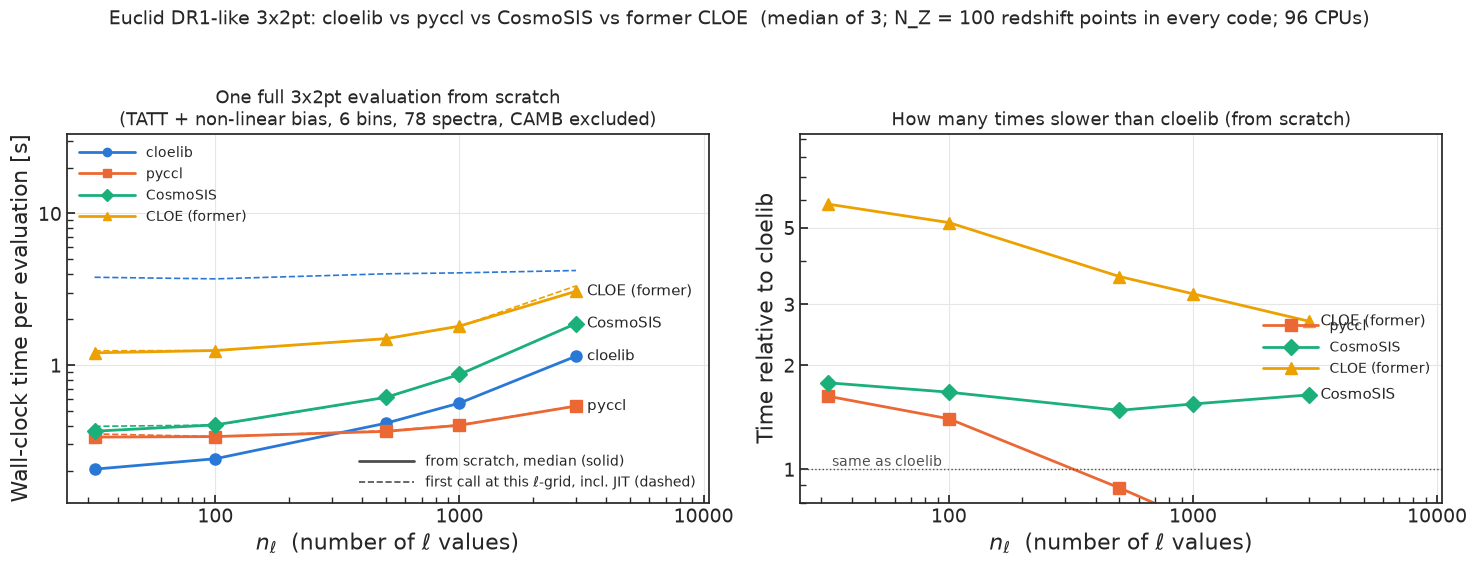

In [14]:
from matplotlib.ticker import FuncFormatter, LogLocator

plain = FuncFormatter(lambda v, _: f'{v:g}')
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax_t, ax_r = axes
nell_arr = np.array(nell_values)
# end-of-line labels: nudge apart labels whose lines end close together
_end = {c: results[c][nell_values[-1]] for c in CODES}
_order = sorted(CODES, key=lambda c: _end[c])
_dy = {c: 0.0 for c in CODES}
for lo, hi in zip(_order, _order[1:]):
    if _end[hi] / _end[lo] < 1.15:
        _dy[lo], _dy[hi] = _dy[lo] - 6, _dy[hi] + 6

for code in CODES:
    t = np.array([results[code][n] for n in nell_values])
    f = np.array([first_call[code][n] for n in nell_values])
    ax_t.plot(nell_arr, t, color=COL[code], lw=2, marker=MARK[code], ms=8)
    ax_t.plot(nell_arr, f, color=COL[code], lw=1.2, ls='--')
    ax_t.annotate(code, (nell_arr[-1], t[-1]), xytext=(8, _dy[code]), textcoords='offset points',
                  va='center', fontsize=11, color='0.15')
ax_t.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
ax_t.set_ylabel('Wall-clock time per evaluation [s]')
ax_t.set_title(f'One full 3x2pt evaluation from scratch\n(TATT + non-linear bias, {n_bins} bins, {N_SPECTRA} spectra, CAMB excluded)', fontsize=13)
ax_t.set_xscale('log'); ax_t.set_yscale('log')
ax_t.set_xlim(nell_arr[0] / 1.3, nell_arr[-1] * 3.5)
ax_t.set_ylim(0.6 * min(min(results[c].values()) for c in CODES),
              40 * max(max(first_call[c].values()) for c in CODES) / 5)   # room above the lines for the legends
ax_t.yaxis.set_major_formatter(plain); ax_t.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ''))
ax_t.xaxis.set_major_formatter(plain)
code_style_legends(ax_t, [(c, COL[c], MARK[c]) for c in CODES], fontsize=10)
ax_t.tick_params(axis='both', which='both', direction='in')
ax_t.grid(True, which='major', color='0.9', lw=0.8)

for code in OTHERS:
    r = np.array([results[code][n] / results['cloelib'][n] for n in nell_values])
    ax_r.plot(nell_arr, r, color=COL[code], lw=2, marker=MARK[code], ms=8, label=code)
    ax_r.annotate(f'{code}', (nell_arr[-1], r[-1]), xytext=(8, 0), textcoords='offset points',
                  va='center', fontsize=11, color='0.15')
ax_r.axhline(1.0, color='0.3', lw=1, ls=':')
ax_r.text(nell_arr[0], 1.0, ' same as cloelib', va='bottom', fontsize=10, color='0.3')
ax_r.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
ax_r.set_ylabel('Time relative to cloelib')
ax_r.set_title('How many times slower than cloelib (from scratch)', fontsize=13)
ax_r.set_xscale('log'); ax_r.set_yscale('log')
ax_r.set_xlim(nell_arr[0] / 1.3, nell_arr[-1] * 3.5)
ax_r.set_ylim(0.8, 1.6 * max(results[c][n] / results['cloelib'][n] for c in OTHERS for n in nell_values))
ax_r.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 3, 5)))
ax_r.yaxis.set_major_formatter(plain); ax_r.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ''))
ax_r.xaxis.set_major_formatter(plain)
ax_r.legend(frameon=False, fontsize=10, loc='center right', bbox_to_anchor=(1.0, 0.42))
ax_r.tick_params(axis='both', which='both', direction='in')
ax_r.grid(True, which='major', color='0.9', lw=0.8)

plt.suptitle(f'Euclid DR1-like 3x2pt: cloelib vs pyccl vs CosmoSIS vs former CLOE  (median of {N_REPEAT}; '
             f'N_Z = {N_Z} redshift points in every code; {THREAD_LABEL})', fontsize=14, y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, f'{FIG_PREFIX}{FIG_SUFFIX}_nell_sweep.png'), dpi=150, bbox_inches='tight')
plt.show()

### 4.1. 8 CPUs (a laptop) vs 96 CPUs (a full, healthy NUMA node)
The same sweep, read back from every `timings_Euclid_DR1_<N>cpu.json` this notebook has written. Each file is one run of the notebook under `taskset` (see *Running this notebook*, top).
- **Left:** time per evaluation from scratch against $n_\ell$. Solid lines with filled markers are the largest CPU budget, dashed lines with open markers the smallest.
- **Right:** how much slower each code is on the smaller budget, $t_{\rm 8\,CPUs}/t_{\rm 96\,CPUs}$. A code that does not use the extra CPUs sits at 1.

8 CPUs is the classical laptop run. It is also roughly what each walker gets when a sampler runs many walkers on one node.


runs found: 8 CPUs (48-55 on drontermeer.strw.leidenuniv.nl), 96 CPUs (48-95,144-191 on drontermeer.strw.leidenuniv.nl)

One full evaluation from scratch [s], median of 3: 96 CPUs / 8 CPUs (slow-down factor 8 vs 96 CPUs)

 n_ell                    cloelib                      pyccl                   CosmoSIS              CLOE (former)
    32    0.206 /   0.156 ( 0.8x)    0.335 /   0.333 ( 1.0x)    0.367 /   0.366 ( 1.0x)    1.206 /   1.202 ( 1.0x)
   100    0.242 /   0.270 ( 1.1x)    0.338 /   0.364 ( 1.1x)    0.404 /   0.402 ( 1.0x)    1.249 /   1.244 ( 1.0x)
   500    0.414 /   0.386 ( 0.9x)    0.366 /   0.520 ( 1.4x)    0.614 /   0.612 ( 1.0x)    1.495 /   1.490 ( 1.0x)
  1000    0.562 /   0.557 ( 1.0x)    0.401 /   0.705 ( 1.8x)    0.869 /   0.870 ( 1.0x)    1.809 /   1.796 ( 1.0x)
  3000    1.145 /   1.224 ( 1.1x)    0.537 /   1.403 ( 2.6x)    1.880 /   1.878 ( 1.0x)    3.067 /   3.069 ( 1.0x)
 first     3.80 /    4.03             0.35 /    0.35             0.40 /    0.39         

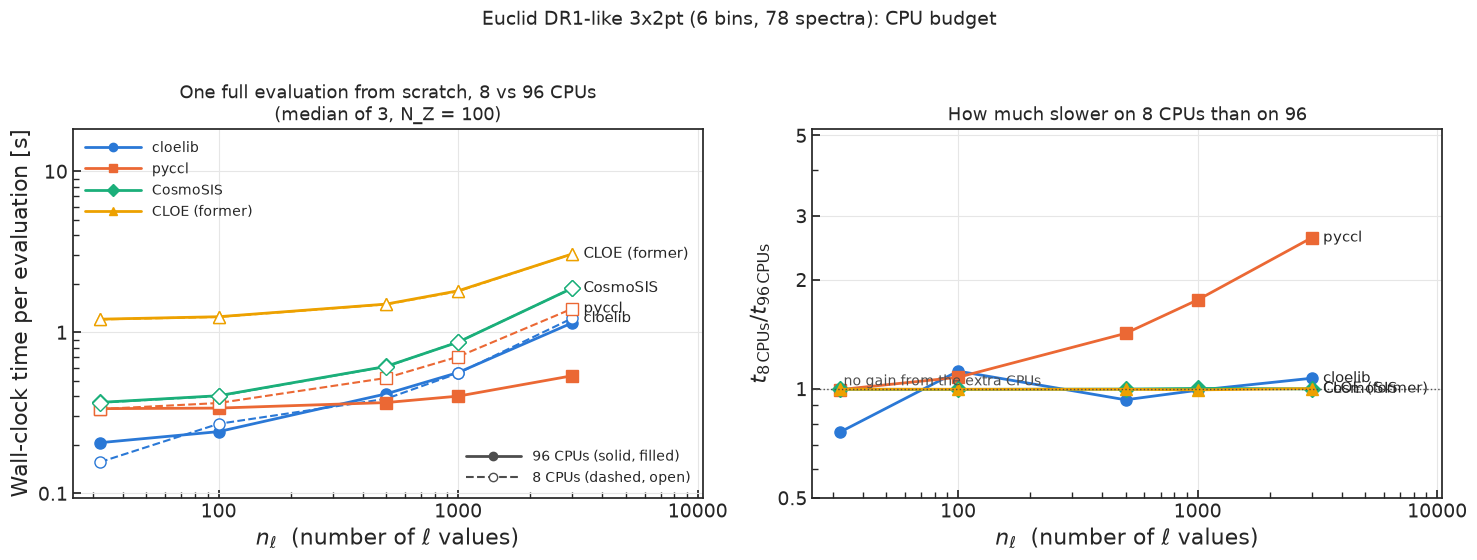

In [15]:
import glob

runs = {}
for fn in glob.glob(os.path.join(RESULTS, 'timings_Euclid_DR1_*cpu.json')):
    with open(fn) as f:
        r = json.load(f)
    for key in ('results', 'first_call'):
        r[key] = {c: {int(n): v for n, v in d.items()} for c, d in r[key].items()}
    runs[r['n_cpu']] = r
budgets = sorted(runs)
print('runs found: ' + ', '.join(f'{n} CPUs ({runs[n]["cpus"]} on {runs[n]["host"]})' for n in budgets))

if len(budgets) < 2:
    print('Only one CPU budget so far: run the notebook on the other one (run.sh).')
else:
    lo, hi = budgets[0], budgets[-1]
    nells = [n for n in runs[hi]['nell_values'] if n in runs[lo]['results']['cloelib']]
    t = {(c, b): np.array([runs[b]['results'][c][n] for n in nells]) for c in CODES for b in (lo, hi)}
    f1 = {(c, b): np.array([runs[b]['first_call'][c][n] for n in nells]) for c in CODES for b in (lo, hi)}

    print(f'\nOne full evaluation from scratch [s], median of {runs[hi]["n_repeat"]}: {hi} CPUs / {lo} CPUs '
          f'(slow-down factor {lo} vs {hi} CPUs)\n')
    print(f'{"n_ell":>6s} ' + ' '.join(f'{c:>26s}' for c in CODES))
    for k, n in enumerate(nells):
        print(f'{n:6d} ' + ' '.join(f'{t[c, hi][k]:8.3f} / {t[c, lo][k]:7.3f} ({t[c, lo][k] / t[c, hi][k]:4.1f}x)'
                                     for c in CODES))
    print(f'{"first":>6s} ' + ' '.join(f'{f1[c, hi][0]:8.2f} / {f1[c, lo][0]:7.2f}        ' for c in CODES)
          + f'   (first call at n_ell = {nells[0]})')
    for b in (hi, lo):
        print(f'\nRelative to cloelib, {b} CPUs: ' + ' | '.join(
            f'n_ell={n}: ' + ', '.join(f'{c} {t[c, b][k] / t["cloelib", b][k]:.1f}x' for c in OTHERS)
            for k, n in enumerate(nells)))

    fig, (ax_t, ax_r) = plt.subplots(1, 2, figsize=(15, 5.5))
    x = np.array(nells)
    for c in CODES:
        ax_t.plot(x, t[c, hi], color=COL[c], marker=MARK[c], ms=8, lw=2)
        ax_t.plot(x, t[c, lo], color=COL[c], marker=MARK[c], ms=8, lw=1.5, ls='--', mfc='white')
        ax_t.annotate(c, (x[-1], max(t[c, hi][-1], t[c, lo][-1])), xytext=(8, 0), textcoords='offset points',
                      va='center', fontsize=11, color='0.15')
        ax_r.plot(x, t[c, lo] / t[c, hi], color=COL[c], marker=MARK[c], ms=8, lw=2)
        ax_r.annotate(c, (x[-1], t[c, lo][-1] / t[c, hi][-1]), xytext=(8, 0), textcoords='offset points',
                      va='center', fontsize=11, color='0.15')
    who = [Line2D([], [], color=COL[c], marker=MARK[c], lw=2, label=c) for c in CODES]
    bud = [Line2D([], [], color='0.3', marker='o', lw=2, label=f'{hi} CPUs (solid, filled)'),
           Line2D([], [], color='0.3', marker='o', mfc='white', lw=1.5, ls='--', label=f'{lo} CPUs (dashed, open)')]
    ax_t.add_artist(ax_t.legend(handles=who, loc='upper left', frameon=False, fontsize=10))
    ax_t.legend(handles=bud, loc='lower right', frameon=False, fontsize=10)
    ax_t.set_xscale('log'); ax_t.set_yscale('log')
    ax_t.set_xlim(x[0] / 1.3, x[-1] * 3.5)
    ax_t.set_ylim(0.6 * min(v.min() for v in t.values()), 6 * max(v.max() for v in t.values()))
    ax_t.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
    ax_t.set_ylabel('Wall-clock time per evaluation [s]')
    ax_t.set_title(f'One full evaluation from scratch, {lo} vs {hi} CPUs\n(median of {runs[hi]["n_repeat"]}, '
                   f'N_Z = {runs[hi]["n_z"]})', fontsize=13)
    ax_r.axhline(1.0, color='0.3', lw=1, ls=':')
    ax_r.text(x[0], 1.0, ' no gain from the extra CPUs', va='bottom', fontsize=10, color='0.3')
    ax_r.set_xscale('log'); ax_r.set_yscale('log')
    ax_r.set_xlim(x[0] / 1.3, x[-1] * 3.5)
    ax_r.set_ylim(0.5, 2 * max(max(t[c, lo] / t[c, hi]) for c in CODES))
    ax_r.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 3, 5)))
    ax_r.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
    ax_r.set_ylabel(f'$t_{{{lo}\\,\\rm CPUs}} / t_{{{hi}\\,\\rm CPUs}}$')
    ax_r.set_title(f'How much slower on {lo} CPUs than on {hi}', fontsize=13)
    for ax in (ax_t, ax_r):
        ax.xaxis.set_major_formatter(plain); ax.yaxis.set_major_formatter(plain)
        ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ''))
        ax.tick_params(axis='both', which='both', direction='in')
        ax.grid(True, which='major', color='0.9', lw=0.8)
    plt.suptitle(f'Euclid DR1-like 3x2pt ({n_bins} bins, {N_SPECTRA} spectra): CPU budget', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES, f'{FIG_PREFIX}_cpu_comparison.png'), dpi=150, bbox_inches='tight')
    plt.show()


**Result: 8 vs 96 CPUs.** Both runs were on NUMA node 1 of `drontermeer`, at full clock and with the load average between 1.6 and 9.4.

| $n_\ell$ | cloelib | pyccl | CosmoSIS | former CLOE |
|---|---|---|---|---|
| 32 | **0.16** / **0.21** s | 0.33 / 0.34 s | 0.37 / 0.37 s | 1.20 / 1.21 s |
| 100 | **0.27** / **0.24** | 0.36 / 0.34 | 0.40 / 0.40 | 1.24 / 1.25 |
| 500 | **0.39** / 0.41 | 0.52 / **0.37** | 0.61 / 0.61 | 1.49 / 1.50 |
| 1000 | **0.56** / 0.56 | 0.71 / **0.40** | 0.87 / 0.87 | 1.80 / 1.81 |
| 3000 | **1.22** / 1.15 | 1.40 / **0.54** | 1.88 / 1.88 | 3.07 / 3.07 |
| first call, $n_\ell=32$ | 4.0 / 3.8 s | 0.35 / 0.35 | 0.39 / 0.40 | 1.23 / 1.24 |

Each cell is 8 CPUs / 96 CPUs, median of 3; bold marks the fastest code on that budget.

- **Only pyccl uses the extra CPUs.** Going from 96 to 8 CPUs makes pyccl 1.0x slower at $n_\ell=32$, 1.4x at 500, 1.8x at 1000 and 2.6x at 3000. CCL's OpenMP loop over $\ell$ inside each of its 177 `angular_cl` calls pays off only once there are many $\ell$ values.
- **CosmoSIS and former CLOE are single-threaded:** their 8- and 96-CPU times agree to within 1%.
- **cloelib does not gain from more CPUs either.** Its 8/96 ratio is 0.8–1.1x, within the run-to-run scatter. As in DR3, XLA's thread pool does not pay off on arrays this small, and the CAMB distance calls are slower with more threads: 0.014 s on 8 CPUs, 0.037 s on 96 (profile, section 5.1).
- **On 8 CPUs, the laptop case, cloelib is the fastest code at every $n_\ell$.** It is 2.1x faster than pyccl at $n_\ell=32$ and 1.1–1.3x faster from $n_\ell=100$ on. It is 1.5–2.3x faster than CosmoSIS and 2.5–7.7x faster than former CLOE.
- **On 96 CPUs, pyccl overtakes cloelib from $n_\ell\approx500$** and is 2.1x faster at $n_\ell=3000$. Below $n_\ell=100$, cloelib is still 1.4–1.6x faster.
- **Noise.** Repeated measurements of the same cloelib configuration below 0.3 s scatter by up to ~±30%. At $n_\ell=32$ and `N_Z = 100` on 8 CPUs, section 4 measured 0.16 s and section 6 measured 0.29 s. Differences below ~0.1 s between the two budgets are not significant.


## 5. Euclid-like $n_\ell = 32$, and where the time goes
Left: one evaluation from scratch for each code at $n_\ell=32$. The black tick marks the first call (cloelib: including JIT compilation).
Right: the same evaluation split into its steps, for the two codes whose structure gives a natural split: the CosmoSIS modules and former CLOE's three steps. cloelib's split is profiled in 5.1.

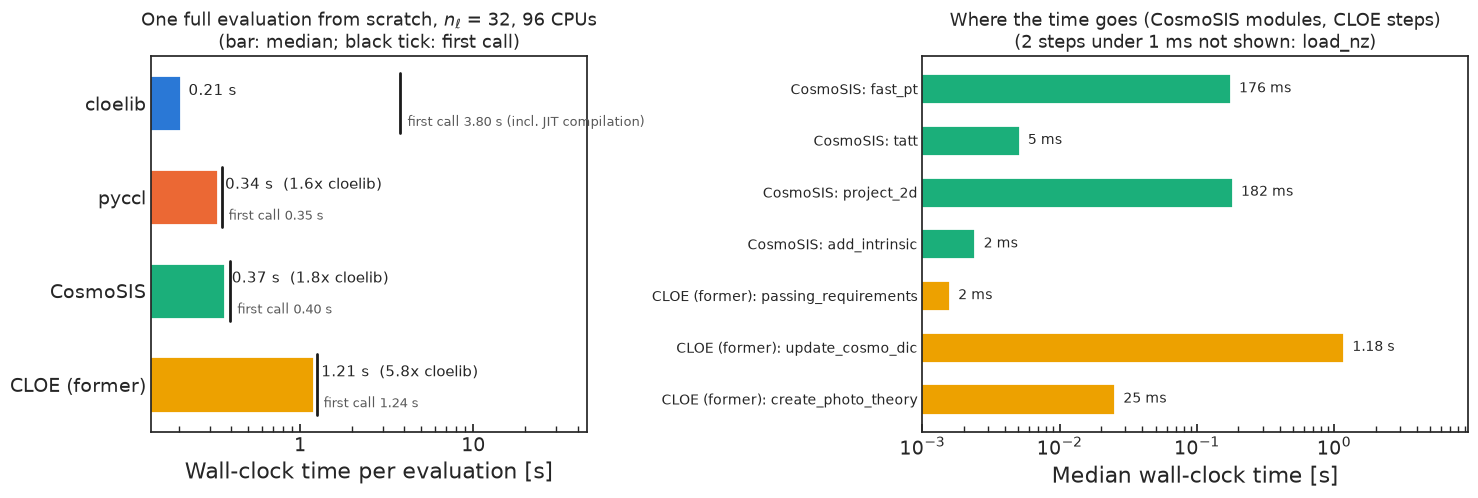

In [16]:
NELL_REF = 32
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={'width_ratios': [1, 1.25]})

ax = axes[0]
y = np.arange(len(CODES))[::-1]
vals = [results[c][NELL_REF] for c in CODES]
ax.barh(y, vals, color=[COL[c] for c in CODES], height=0.6, edgecolor='white', linewidth=2)
for yi, c, v in zip(y, CODES, vals):
    rel = '' if c == 'cloelib' else f'  ({v / results["cloelib"][NELL_REF]:.1f}x cloelib)'
    ax.text(v * 1.1, yi + 0.13, f'{v:.2f} s{rel}', va='center', fontsize=11, color='0.15')
    f = first_call[c][NELL_REF]
    ax.plot([f, f], [yi - 0.32, yi + 0.32], color='0.1', lw=2)        # first-call tick
    note = ' (incl. JIT compilation)' if c == 'cloelib' else ''
    ax.text(f * 1.1, yi - 0.2, f'first call {f:.2f} s{note}', va='center', fontsize=9, color='0.35')
ax.set_yticks(y); ax.set_yticklabels(CODES)
ax.set_xscale('log')
ax.set_xlim(min(vals) / 1.5, max(first_call[c][NELL_REF] for c in CODES) * 12)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
ax.set_xlabel('Wall-clock time per evaluation [s]')
ax.set_title(f'One full evaluation from scratch, $n_\\ell$ = {NELL_REF}, {THREAD_LABEL}\n(bar: median; black tick: first call)', fontsize=13)
ax.tick_params(axis='both', which='both', direction='in')

ax = axes[1]
rows = ([('CosmoSIS', m, cs_breakdown[NELL_REF][m]) for m in TIMED_MODULES]
        + [('CLOE (former)', m, v) for m, v in cloe_parts[NELL_REF].items()])
_n_small = sum(1 for r in rows if r[2] < 1e-3)
rows = [r for r in rows if r[2] >= 1e-3]          # load_nz modules take < 1 ms
y = np.arange(len(rows))[::-1]
ax.barh(y, [r[2] for r in rows], color=[COL[r[0]] for r in rows], height=0.6, edgecolor='white', linewidth=2)
for yi, (c, m, v) in zip(y, rows):
    ax.text(max(v, 1e-3) * 1.15, yi, f'{v * 1e3:.0f} ms' if v < 1 else f'{v:.2f} s', va='center', fontsize=10, color='0.15')
ax.set_yticks(y); ax.set_yticklabels([f'{c}: {m}' for c, m, _ in rows], fontsize=10)
ax.set_xscale('log'); ax.set_xlim(1e-3, max(r[2] for r in rows) * 8)
ax.set_xlabel('Median wall-clock time [s]')
ax.set_title('Where the time goes (CosmoSIS modules, CLOE steps)'
             + (f'\n({_n_small} steps under 1 ms not shown: load_nz)' if _n_small else ''), fontsize=13)
ax.tick_params(axis='both', which='both', direction='in')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES, f'{FIG_PREFIX}{FIG_SUFFIX}_nell32.png'), dpi=150, bbox_inches='tight')
plt.show()

### 5.1. Where does cloelib's time go?
A `cProfile` of one cloelib evaluation from scratch at $n_\ell=32$, after compilation. Self-time is grouped by the library it is spent in:
- **FAST-PT:** the `fastpt` package.
- **CAMB library calls:** background distances and P(k) interpolation through `CAMBBackground` / `CAMB*Perturbations`, not a Boltzmann run.
- **JAX/XLA:** dispatch and the compiled Limber kernels.
- **everything else.**

In [17]:
import cProfile
import pstats

ells_32 = np.geomspace(2, 2999, NELL_REF)
cloelib_3x2pt(*build_cloelib(), ells_32)   # compile first
prof = cProfile.Profile()
prof.enable()
cloelib_3x2pt(*build_cloelib(), ells_32)
prof.disable()
st = pstats.Stats(prof)
groups = {'FAST-PT': 0.0, 'CAMB library calls': 0.0, 'JAX/XLA': 0.0, 'everything else': 0.0}
for (fname, _, _), (_, _, tottime, _, _) in st.stats.items():
    key = ('FAST-PT' if '/fastpt/' in fname else
           'CAMB library calls' if '/camb/' in fname else
           'JAX/XLA' if ('/jax/' in fname or '/jaxlib/' in fname) else 'everything else')
    groups[key] += tottime
total = st.total_tt
print(f'cloelib evaluation from scratch (profiled): {total:.3f} s')
for k, v in groups.items():
    print(f'  {k:20s} {v:6.3f} s  ({v / total * 100:4.1f}%)')
st.sort_stats('cumulative').print_stats(15)

cloelib evaluation from scratch (profiled): 0.267 s
  FAST-PT               0.068 s  (25.4%)
  CAMB library calls    0.037 s  (13.8%)
  JAX/XLA               0.066 s  (24.8%)
  everything else       0.096 s  (36.0%)


         242526 function calls (242304 primitive calls) in 0.267 seconds

   Ordered by: cumulative time
   List reduced from 853 to 15 due to restriction <15>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      3/2    0.000    0.000    0.267    0.134 <WORKDIR>/env/cloe-cosmosis/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3786(run_code)
        2    0.000    0.000    0.267    0.134 {built-in method builtins.exec}
        1    0.000    0.000    0.264    0.264 <TMP>
      6/3    0.000    0.000    0.264    0.088 <WORKDIR>/cloelib-384-nonlinear-bias/cloelib/profiling/profiling.py:70(wrapper)
        3    0.000    0.000    0.264    0.088 <WORKDIR>/cloelib-384-nonlinear-bias/cloelib/summary_statistics/angular_two_point.py:636(get_Cl)
        3    0.000    0.000    0.228    0.076 <WORKDIR>/cloelib-384-nonlinear-bias/cloelib/summary_statistics/angular_two_point.py:587(get_Cl_tensor)
        3    0.003    0.001    0.226    0.075 <WORKDIR>/cloelib-384

### 5.2. Timing results
The full table, 8 CPUs against 96 CPUs, is in section 4.1. Where the time goes at $n_\ell=32$ is the same on both budgets:
- **cloelib** (0.22 s profiled on 8 CPUs): FAST-PT 30%, JAX/XLA 24%, CAMB library calls 6%, Python glue 40%. On 96 CPUs (0.27 s) the CAMB calls take 14%, for the thread start-up reason given in section 4.1.
- **CosmoSIS:** `fast_pt` costs a fixed 0.18 s. `project_2d` grows from 0.18 s at $n_\ell=32$ to 1.69 s at $n_\ell=3000$.
- **Former CLOE:** `update_cosmo_dic` costs a fixed 1.18 s, the same as for 13 bins: it does not depend on the number of bins. `create_photo_theory` grows from 0.025 s to 1.88 s.

**DR1 vs DR3.** The DR1 3x2pt has 4.5x fewer spectra than DR3 (78 vs 351), but no code gets 4.5x faster at $n_\ell=32$, because the bin-independent work dominates: FAST-PT, interpolators and set-up.
- cloelib: 0.16–0.21 s vs 0.25–0.32 s.
- CosmoSIS: 0.37 s vs 0.77 s.
- Former CLOE: 1.20 s vs 1.26 s.

The DR3 runs were made on a different machine with 128 CPUs, so this cross-comparison is indicative only.


## 6. Varying the number of redshift points, $N_Z$, at $n_\ell = 32$
Same protocol as section 4 (one full evaluation from scratch, CAMB excluded, median of `N_REPEAT`, plus the first call), at the Euclid-like $n_\ell = 32$. Here the common number of redshift points `N_Z` (section 1.1) varies, and it still applies to **every** code: n(z), the Limber integral and the $P(k,z)$ / PT redshift grid.

CAMB accepts at most 256 redshifts (`camb.model.max_transfer_redshifts`), and every code passes its $P(k,z)$ grid to CAMB, so `N_Z` stops at 250.
For each `N_Z`, the cell rebuilds everything that depends on it. All of this is untimed:
- the n(z) files;
- cloelib's `CAMB*Perturbations` on the new `zs`;
- pyccl's spline parameters, `DCHI`, and its CAMB run;
- CosmoSIS's pipeline and post-CAMB block;
- former CLOE's subprocess.

It then times the four codes as in section 4.

**Convergence.** Timing alone does not tell whether a given `N_Z` is enough, so the cell also keeps the six check spectra of section 3 at every `N_Z`. The second panel shows each code's change against **its own** spectra at the largest `N_Z`: $\max_{\ell>20}|C_\ell(N_Z)/C_\ell(250)-1|$ over the six spectra. That is the self-convergence of each code's redshift integration.

In [18]:
NZ_VALUES = [100, 150, 200, 250]
NELL_NZ = 32
ells_nz = np.geomspace(2, 2999, NELL_NZ)


def setup_for_nz(n):
    """Rebuild every N_Z-dependent input of the four codes (untimed). Returns the CosmoSIS pipeline."""
    global N_Z, zs, z_pk, my_dndz_norm, dndz_norm, nonlin_pert, lin_pert, CHI_MIN, CHI_MAX, DCHI
    global cosmo_camb, PK_LIN, PK_NL, a_pt, _one, block_cosmo
    N_Z = n
    zs = np.linspace(1e-4, ZMAX, n)
    z_pk = np.linspace(0.0, ZMAX, n)
    my_dndz_norm = np.vstack([np.interp(zs, z_nz, dndz_native[k]) for k in bin_keys])
    my_dndz_norm /= integrate.trapezoid(my_dndz_norm, zs, axis=1)[:, None]
    dndz_norm = {k: my_dndz_norm[i] for i, k in enumerate(bin_keys)}
    _one = np.ones_like(zs)
    np.savetxt(nz_txt, np.column_stack([zs, my_dndz_norm.T]), header=f'z n_1 ... n_{n_bins}, {n} points')
    np.savetxt(os.path.join(CLOE_PHOT_DIR, f'nzDR1_zs{n}.dat'),
               np.column_stack([zs, my_dndz_norm.T]), delimiter='\t',
               header='z ' + ' '.join(f'n{i + 1}' for i in range(n_bins)))
    # cloelib (CAMB)
    nonlin_pert = CAMBNonLinearPerturbations(make_background(), None, zs, nonlinear_model='mead2020')
    lin_pert = CachedCAMBLinearPerturbations(make_background(), zs)
    CHI_MIN, CHI_MAX = np.asarray(nonlin_pert.background.comoving_distance(np.array([zs[0], ZMAX])), dtype=float)
    DCHI = (CHI_MAX - CHI_MIN) / (n - 1)
    # pyccl (spline parameters, then CAMB)
    ccl.spline_params.A_SPLINE_NA_PK = n - 1
    ccl.spline_params.DCHI_INTEGRATION = DCHI
    cosmo_camb = ccl.Cosmology(**CCL_PARAMS, transfer_function='boltzmann_camb', matter_power_spectrum='camb',
                               extra_parameters={'camb': {'halofit_version': 'mead2020', 'kmax': 500}})
    cosmo_camb.compute_nonlin_power()
    a_, lk_, pk_ = cosmo_camb.get_linear_power().get_spline_arrays()
    PK_LIN = {'a': a_, 'k': np.exp(lk_), 'delta_matter:delta_matter': pk_}
    a_, lk_, pk_ = cosmo_camb.get_nonlin_power().get_spline_arrays()
    PK_NL = {'a': a_, 'k': np.exp(lk_), 'delta_matter:delta_matter': pk_}
    a_pt = np.sort(1.0 / (1.0 + z_pk))
    # CosmoSIS (uses N_Z, DCHI and the n(z) file written above)
    pipe = make_cosmosis_pipeline(NELL_NZ)
    block_cosmo = run_modules(pipe, CAMB_MODULES, pipe.build_starting_block([]))
    return pipe


def check_spectra(code, out):
    """The six section-3 check spectra from one evaluation's output."""
    global _cl, _cc, _b, cloe_former_spectra
    if code == 'cloelib':
        _cl = out
    elif code == 'pyccl':
        _cc = out
    elif code == 'CosmoSIS':
        _b = out
    else:
        cloe_former_spectra = out
    return {chk: np.asarray(get_spectrum(code, *chk)) for chk in checks}


nz_results = {c: {} for c in CODES}
nz_first = {c: {} for c in CODES}
nz_spec = {c: {} for c in CODES}
nz_grids, nz_load = {}, {}

for n in NZ_VALUES:
    t_set = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        pipe = setup_for_nz(n)
    t_set = time.time() - t_set

    # former CLOE: subprocess at this N_Z
    json_n = os.path.join(RESULTS, f'cloe_former_DR1_timings_nz{n}{FIG_SUFFIX}.json')
    npz_n = os.path.join(RESULTS, f'cloe_former_DR1_spectra_nell32_nz{n}{FIG_SUFFIX}.npz')
    load_start = wait_for_quiet()
    proc = subprocess.run([CLOE_PY, str(tp.CLOE_FORMER_BENCHMARK), '--nell', str(NELL_NZ),
                           '--repeat', str(N_REPEAT), '--out', json_n, '--spectra-out', npz_n,
                           '--n-z', str(n), '--z-max', str(ZMAX), '--nz-file', f'nzDR1_zs{n}.dat', *CLOE_ARGS],
                          capture_output=True, text=True, env=env_cloe, cwd=str(tp.TP))
    assert proc.returncode == 0, proc.stderr[-3000:]
    with open(json_n) as f:
        cj = json.load(f)
    nz_results['CLOE (former)'][n] = cj['from_scratch'][str(NELL_NZ)]
    nz_first['CLOE (former)'][n] = cj['first_call'][str(NELL_NZ)]
    nz_spec['CLOE (former)'][n] = check_spectra('CLOE (former)', dict(np.load(npz_n)))

    # cloelib, pyccl, CosmoSIS
    load_mid = wait_for_quiet()
    nz_first['cloelib'][n], nz_results['cloelib'][n] = first_and_median(
        lambda: cloelib_3x2pt(*build_cloelib(), ells_nz), clear_jit=True)
    nz_first['pyccl'][n], nz_results['pyccl'][n] = first_and_median(lambda: pyccl_from_scratch(ells_nz))
    CS_LIMBER_POINTS.clear()
    nz_first['CosmoSIS'][n], nz_results['CosmoSIS'][n] = first_and_median(
        lambda: run_modules(pipe, TIMED_MODULES, block_cosmo.clone()))
    nz_spec['cloelib'][n] = check_spectra('cloelib', cloelib_3x2pt(*build_cloelib(), ells_nz))
    nz_spec['pyccl'][n] = check_spectra('pyccl', pyccl_from_scratch(ells_nz))
    nz_spec['CosmoSIS'][n] = check_spectra('CosmoSIS', run_modules(pipe, TIMED_MODULES, block_cosmo.clone()))

    nz_load[n] = (load_start, load_mid, os.getloadavg()[0])
    nz_grids[n] = dict(cloelib=len(zs), pyccl_pk=len(ccl.pyutils.get_pk_spline_a(fresh_ccl_cosmo())),
                       cs_pk=len(block_cosmo['matter_power_nl', 'z']), cs_limber_median=int(np.median(CS_LIMBER_POINTS)),
                       cloe_limber=cj['n_z_limber'], cloe_pk=cj['n_z'])
    print(f'N_Z={n:4d} | ' + ' | '.join(f'{c} {nz_results[c][n]:6.3f}s (first {nz_first[c][n]:5.2f}s)' for c in CODES)
          + f'   [set-up {t_set:.0f} s; load {nz_load[n][0]:.1f}/{nz_load[n][1]:.1f}/{nz_load[n][2]:.1f}]')

print('\nGrid sizes actually used:')
for n in NZ_VALUES:
    g = nz_grids[n]
    print(f'  N_Z={n:4d}: cloelib zs {g["cloelib"]} | pyccl P(k,a) {g["pyccl_pk"]} | CosmoSIS P(k,z) {g["cs_pk"]}, '
          f'Limber points/spectrum (median) {g["cs_limber_median"]} | CLOE Limber {g["cloe_limber"]}, P(k,z) {g["cloe_pk"]}')

Note: redshifts have been re-sorted (earliest first)


Note: redshifts have been re-sorted (earliest first)



Setting up module consistency
------------------------------



Setting up module camb
-----------------------



Setting up module load_nz_lens
-------------------------------


...


Setting up module project_2d
-----------------------------


Calculating Limber: Kernel 1 = ('W', 'source'), Kernel 2 = ('W', 'source'), P_3D = MatterPower3D, section = matter_power_nl --> Output: shear_cl
Calculating Limber: Kernel 1 = ('W', 'source'), Kernel 2 = ('N', 'source'), P_3D = MatterIntrinsicPower3D, section = matter_intrinsic_power --> Output: shear_cl_gi
Calculating Limber: Kernel 1 = ('N', 'source'), Kernel 2 = ('N', 'source'), P_3D = IntrinsicPower3D, section = intrinsic_power --> Output: shear_cl_ii
Calculating Limber: Kernel 1 = ('N', 'lens'), Kernel 2 = ('N', 'source'), P_3D = MatterIntrinsicPower3D, section = matter_intrinsic_power --> Output: galaxy_intrinsic_cl
Calculating Limber: Kernel 1 = ('N', 'lens'), Kernel 2 = ('N', 'lens'), P_3D = MatterPower3D, section = matter_power_nl --> Output: galaxy_cl
Calculating Limber: Kernel 1 = ('N', 'lens'), Kernel 2 = ('W', 'source'), P_3D = MatterPower3D, section = matter_power_nl --> Output: galaxy_shear_cl
Will project these spectra into 2D:
    -  shear_cl
    -  shear_cl_gi
    -  


The add_intrinsic module will try to combine IA terms into these spectra:
 - shear-shear.
 - position-shear.

Setup all pipeline modules




Parameter Priors
----------------
cosmological_parameters--h0                     ~ delta(0.7)
cosmological_parameters--omega_m                ~ delta(0.3)
cosmological_parameters--omega_b                ~ delta(0.05)
cosmological_parameters--omega_k                ~ delta(0.0)
cosmological_parameters--w                      ~ delta(-1.0)
cosmological_parameters--wa                     ~ delta(0.0)
cosmological_parameters--n_s                    ~ delta(0.96)
cosmological_parameters--a_s                    ~ delta(2e-09)
cosmological_parameters--mnu                    ~ delta(0.06)
cosmological_parameters--num_massive_neutrinos  ~ delta(1)
cosmological_parameters--nnu                    ~ delta(3.044)
cosmological_parameters--tau                    ~ delta(0.0544)
intrinsic_alignment_parameters--a1              ~ delta(1.72)
intrinsic_alignment_parameters--alpha1          ~ delta(-0.41)
intrinsic_alignment_parameters--a2              ~ delta(0.4)
intrinsic_alignment_parameters--alpha2

N_Z= 250 | cloelib  0.285s (first  4.06s) | pyccl  0.397s (first  0.40s) | CosmoSIS  0.587s (first  0.59s) | CLOE (former)  2.089s (first  2.12s)   [set-up 22 s; load 10.6/7.4/7.0]

Grid sizes actually used:
  N_Z= 100: cloelib zs 100 | pyccl P(k,a) 100 | CosmoSIS P(k,z) 100, Limber points/spectrum (median) 14 | CLOE Limber 100, P(k,z) 100
  N_Z= 150: cloelib zs 150 | pyccl P(k,a) 150 | CosmoSIS P(k,z) 150, Limber points/spectrum (median) 21 | CLOE Limber 150, P(k,z) 150
  N_Z= 200: cloelib zs 200 | pyccl P(k,a) 200 | CosmoSIS P(k,z) 200, Limber points/spectrum (median) 27 | CLOE Limber 200, P(k,z) 200
  N_Z= 250: cloelib zs 250 | pyccl P(k,a) 250 | CosmoSIS P(k,z) 250, Limber points/spectrum (median) 34 | CLOE Limber 250, P(k,z) 250


n_ell = 32: one full evaluation from scratch [s] (median of 3) | first call [s]

  N_Z        cloelib          pyccl       CosmoSIS  CLOE (former)          cloelib first          pyccl first       CosmoSIS first  CLOE (former) first
  100          0.204          0.340          0.377          1.204                  3.931                0.349                0.391                1.266
  150          0.240          0.358          0.445          1.478                  3.839                0.362                0.448                1.555
  200          0.270          0.379          0.514          1.773                  3.989                0.379                0.519                1.805
  250          0.285          0.397          0.587          2.089                  4.060                0.396                0.589                2.125

Self-convergence: max over 6 check spectra and ell > 20 of |C(N_Z) / C(250) - 1| [%]

  N_Z        cloelib          pyccl       CosmoSIS  CLOE (former)
  100 

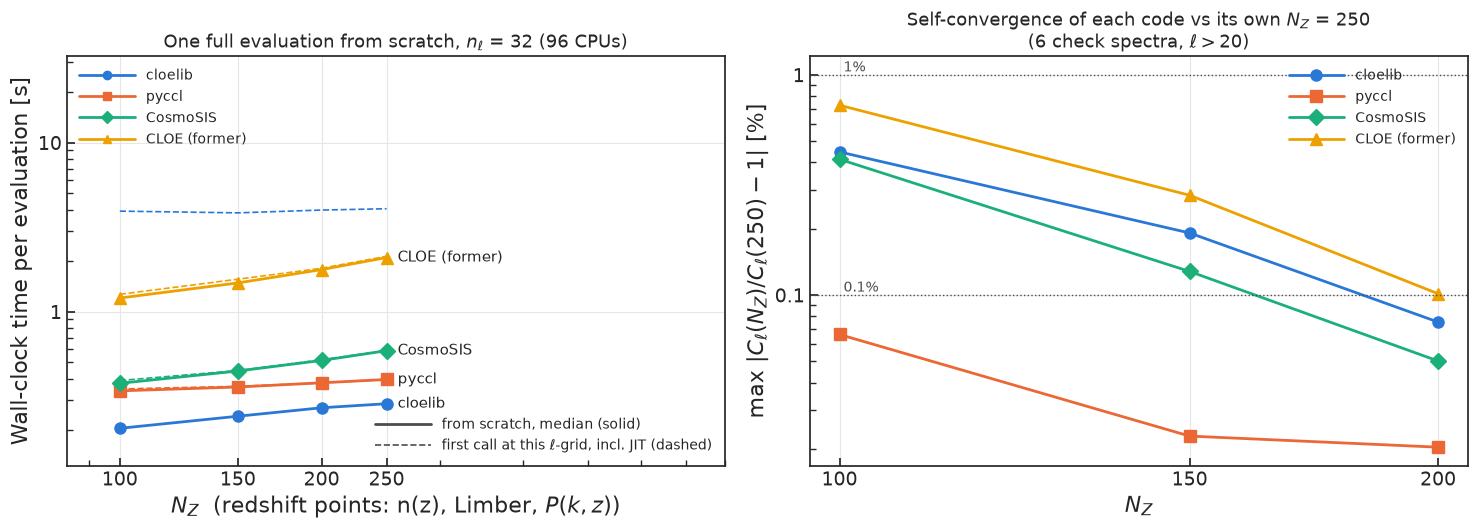

In [19]:
n_ref = NZ_VALUES[-1]
nz_conv = {c: {} for c in CODES}
for c in CODES:
    for n in NZ_VALUES:
        devs = []
        for chk in checks:
            a, b = nz_spec[c][n][chk], nz_spec[c][n_ref][chk]
            m = ells_nz > 20
            devs.append(np.max(np.abs(a[m] / b[m] - 1)))
        nz_conv[c][n] = 100 * max(devs)

print(f'n_ell = {NELL_NZ}: one full evaluation from scratch [s] (median of {N_REPEAT}) | first call [s]\n')
print(f'{"N_Z":>5s} ' + ' '.join(f'{c:>14s}' for c in CODES) + '   ' + ' '.join(f'{c + " first":>20s}' for c in CODES))
for n in NZ_VALUES:
    print(f'{n:5d} ' + ' '.join(f'{nz_results[c][n]:14.3f}' for c in CODES) + '   '
          + ' '.join(f'{nz_first[c][n]:20.3f}' for c in CODES))
print(f'\nSelf-convergence: max over 6 check spectra and ell > 20 of |C(N_Z) / C({n_ref}) - 1| [%]\n')
print(f'{"N_Z":>5s} ' + ' '.join(f'{c:>14s}' for c in CODES))
for n in NZ_VALUES:
    print(f'{n:5d} ' + ' '.join(f'{nz_conv[c][n]:14.3f}' for c in CODES))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax_t, ax_c = axes
nzs = np.array(NZ_VALUES)
for c in CODES:
    t = np.array([nz_results[c][n] for n in NZ_VALUES])
    ax_t.plot(nzs, t, color=COL[c], lw=2, marker=MARK[c], ms=8)
    ax_t.plot(nzs, [nz_first[c][n] for n in NZ_VALUES], color=COL[c], lw=1.2, ls='--')
    ax_t.annotate(c, (nzs[-1], t[-1]), xytext=(8, 0), textcoords='offset points', va='center', fontsize=11, color='0.15')
ax_t.set_xscale('log'); ax_t.set_yscale('log')
ax_t.set_xlim(nzs[0] / 1.2, nzs[-1] * 3.2)
ax_t.set_ylim(0.6 * min(min(v.values()) for v in nz_results.values()),
              8 * max(max(v.values()) for v in nz_first.values()))
ax_t.xaxis.set_major_formatter(plain); ax_t.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: ''))
ax_t.set_xticks(NZ_VALUES)
ax_t.yaxis.set_major_formatter(plain); ax_t.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ''))
ax_t.set_xlabel(r'$N_Z$  (redshift points: n(z), Limber, $P(k,z)$)')
ax_t.set_ylabel('Wall-clock time per evaluation [s]')
ax_t.set_title(f'One full evaluation from scratch, $n_\\ell$ = {NELL_NZ} ({THREAD_LABEL})', fontsize=13)
code_style_legends(ax_t, [(c, COL[c], MARK[c]) for c in CODES], fontsize=10)
ax_t.tick_params(axis='both', which='both', direction='in')
ax_t.grid(True, which='major', color='0.9', lw=0.8)

for c in CODES:
    nn = nzs[:-1]
    cv = np.array([nz_conv[c][n] for n in nn])
    ax_c.plot(nn, cv, color=COL[c], lw=2, marker=MARK[c], ms=8, label=c)
ax_c.axhline(1.0, color='0.3', lw=1, ls=':')
ax_c.text(nzs[0], 1.0, ' 1%', va='bottom', fontsize=10, color='0.3')
ax_c.axhline(0.1, color='0.3', lw=1, ls=':')
ax_c.text(nzs[0], 0.1, ' 0.1%', va='bottom', fontsize=10, color='0.3')
ax_c.set_xscale('log'); ax_c.set_yscale('log')
ax_c.set_xticks(NZ_VALUES[:-1]); ax_c.xaxis.set_major_formatter(plain)
ax_c.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: ''))
ax_c.yaxis.set_major_formatter(plain)
ax_c.set_xlabel(r'$N_Z$')
ax_c.set_ylabel(f'max $|C_\\ell(N_Z)/C_\\ell({n_ref})-1|$ [%]')
ax_c.set_title(f'Self-convergence of each code vs its own $N_Z$ = {n_ref}\n(6 check spectra, $\\ell > 20$)', fontsize=13)
ax_c.legend(frameon=False, fontsize=10)
ax_c.tick_params(axis='both', which='both', direction='in')
ax_c.grid(True, which='major', color='0.9', lw=0.8)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES, f'{FIG_PREFIX}{FIG_SUFFIX}_nz_sweep.png'), dpi=150, bbox_inches='tight')
plt.show()

**Result: cost and convergence vs the number of redshift points** ($n_\ell=32$; times are 8 CPUs / 96 CPUs):

| `N_Z` | cloelib | pyccl | CosmoSIS | former CLOE |
|---|---|---|---|---|
| 100 | 0.29 / 0.20 s | 0.34 / 0.34 s | 0.37 / 0.38 s | 1.21 / 1.20 s |
| 250 | 0.27 / 0.29 s | 0.40 / 0.40 s | 0.58 / 0.59 s | 2.08 / 2.09 s |
| change at 100 vs own 250 | 0.45% | 0.07% | 0.41% | 0.73% |
| change at 200 vs own 250 | 0.08% | 0.02% | 0.05% | 0.10% |

- **Cost.** cloelib and pyccl barely change between 100 and 250 points. CosmoSIS grows 1.6x and former CLOE 1.7x. cloelib's first call (JAX compilation) is 3.8–4.2 s at every `N_Z`.
- **Convergence.** Every code is within 0.75% of its own `N_Z = 250` result at `N_Z = 100`, and within 0.1% at 200. In DR3, cloelib showed a 6.5% "change". That came from the zero crossing of the $\sigma^4$-subtracted GG 1-1 spectrum, not from the integration (section 6 of the DR3 notebook). The DR1 check spectra do not show it, and cloelib converges like the other codes.
- The timing comparison at `N_Z = 100` is therefore also a comparison at comparable accuracy.


## 7. Summary: which code is faster, and which is easier to use?
The figure condenses the notebook into one page for someone choosing a code, for example a new student.
- **Left:** the measured cost of one full evaluation from scratch at the Euclid-like $n_\ell=32$ and at the largest $n_\ell$ of the sweep (3000), relative to the fastest code.
- **Right:** a scorecard. The two time columns are measurements from section 4. The other columns record what it took to run each code for **this** comparison, from sections 0–2.4.
  - The ratings are an assessment of that experience, not a measurement; the text in each cell says why.
  - Ratings: ✓ = good, ~ = workable with effort, ✗ = a real obstacle.

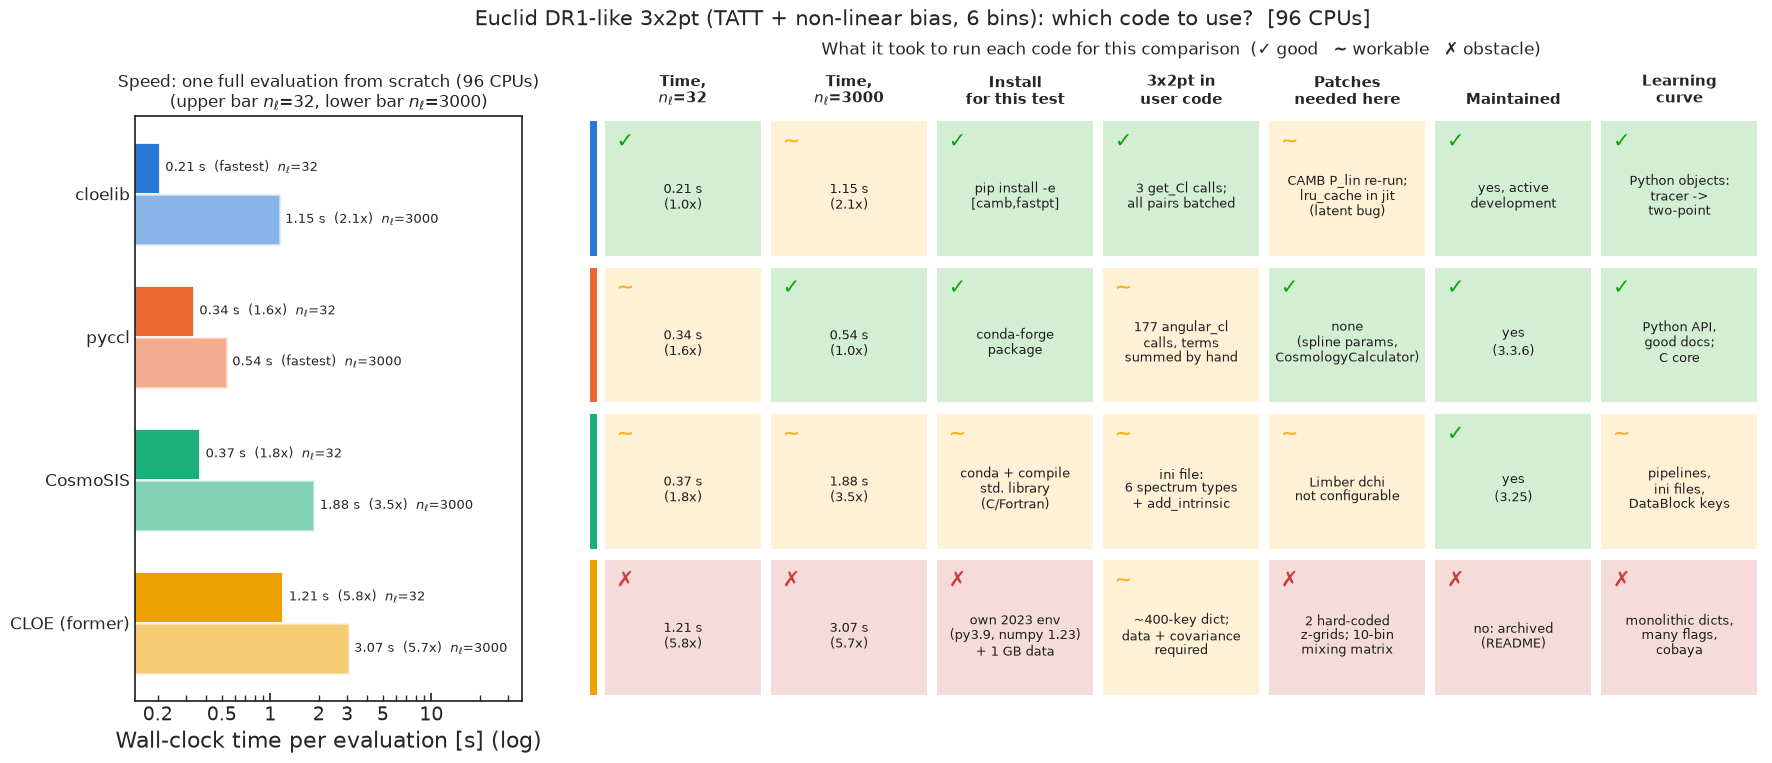

In [20]:
from matplotlib.patches import Rectangle

STATUS = {'good': ('#0ca30c', '✓'), 'mixed': ('#fab219', '~'), 'poor': ('#d03b3b', '✗')}


def time_rating(code, nell):
    r = results[code][nell] / min(results[c][nell] for c in CODES)
    return ('good' if r <= 1.5 else 'mixed' if r <= 5 else 'poor'), f'{results[code][nell]:.2f} s ({r:.1f}x)'


QUAL = {   # (rating, why) per criterion, from setting up each code for this notebook
    'Install\nfor this test': {
        'cloelib': ('good', 'pip install -e\n[camb,fastpt]'),
        'pyccl': ('good', 'conda-forge\npackage'),
        'CosmoSIS': ('mixed', 'conda + compile\nstd. library\n(C/Fortran)'),
        'CLOE (former)': ('poor', 'own 2023 env\n(py3.9, numpy 1.23)\n+ 1 GB data')},
    '3x2pt in\nuser code': {
        'cloelib': ('good', '3 get_Cl calls;\nall pairs batched'),
        'pyccl': ('mixed', f'{N_CCL_CALLS} angular_cl\ncalls, terms\nsummed by hand'),
        'CosmoSIS': ('mixed', 'ini file:\n6 spectrum types\n+ add_intrinsic'),
        'CLOE (former)': ('mixed', '~400-key dict;\ndata + covariance\nrequired')},
    'Patches\nneeded here': {
        'cloelib': ('mixed', 'CAMB P_lin re-run;\nlru_cache in jit\n(latent bug)'),
        'pyccl': ('good', 'none\n(spline params,\nCosmologyCalculator)'),
        'CosmoSIS': ('mixed', 'Limber dchi\nnot configurable'),
        'CLOE (former)': ('poor', '2 hard-coded\nz-grids; 10-bin\nmixing matrix')},
    'Maintained': {
        'cloelib': ('good', 'yes, active\ndevelopment'),
        'pyccl': ('good', 'yes\n(3.3.6)'),
        'CosmoSIS': ('good', 'yes\n(3.25)'),
        'CLOE (former)': ('poor', 'no: archived\n(README)')},
    'Learning\ncurve': {
        'cloelib': ('good', 'Python objects:\ntracer ->\ntwo-point'),
        'pyccl': ('good', 'Python API,\ngood docs;\nC core'),
        'CosmoSIS': ('mixed', 'pipelines,\nini files,\nDataBlock keys'),
        'CLOE (former)': ('poor', 'monolithic dicts,\nmany flags,\ncobaya')},
}
NELL_HI = nell_values[-1]
criteria = [f'Time,\n$n_\\ell$={n}' for n in (32, NELL_HI)] + list(QUAL)

fig = plt.figure(figsize=(21, 7.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 3.0], wspace=0.10)

# Left: absolute time per evaluation, two ell-grids; label = seconds and factor vs the fastest at that n_ell
ax = fig.add_subplot(gs[0])
y = np.arange(len(CODES))[::-1]
h = 0.36
for off, nell, alpha in ((h / 2, 32, 1.0), (-h / 2, NELL_HI, 0.55)):
    best = min(results[c][nell] for c in CODES)
    vals = [results[c][nell] for c in CODES]
    ax.barh(y + off, vals, height=h, color=[COL[c] for c in CODES], alpha=alpha, edgecolor='white', linewidth=2)
    for yi, v in zip(y + off, vals):
        tag = 'fastest' if v == best else f'{v / best:.1f}x'
        ax.text(v * 1.08, yi, f'{v:.2f} s  ({tag})  $n_\\ell$={nell}', va='center', fontsize=9.5, color='0.15')
ax.set_yticks(y); ax.set_yticklabels(CODES, fontsize=12)
ax.set_xscale('log')
ax.set_xlim(0.7 * min(results[c][n] for c in CODES for n in (32, NELL_HI)),
            12 * max(results[c][n] for c in CODES for n in (32, NELL_HI)))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: f'{v:g}' if v in (0.2, 0.3, 0.5, 2, 3, 5) else ''))
ax.set_xlabel('Wall-clock time per evaluation [s] (log)')
ax.set_title(f'Speed: one full evaluation from scratch ({THREAD_LABEL})\n(upper bar $n_\\ell$=32, lower bar $n_\\ell$={NELL_HI})',
             fontsize=12)
ax.tick_params(axis='both', which='both', direction='in')

# Right: scorecard
ax = fig.add_subplot(gs[1])
ax.set_xlim(0, len(criteria)); ax.set_ylim(0, len(CODES)); ax.axis('off')
for j, crit in enumerate(criteria):
    ax.text(j + 0.5, len(CODES) + 0.06, crit, ha='center', va='bottom', fontsize=11, fontweight='bold',
            color='0.15', linespacing=1.1)
    for i, code in enumerate(CODES):
        yy = len(CODES) - 1 - i
        if crit.startswith('Time'):
            rating, why = time_rating(code, 32 if '=32' in crit else NELL_HI)
            why = why.replace(' (', '\n(')
        else:
            rating, why = QUAL[crit][code]
        col, icon = STATUS[rating]
        ax.add_patch(Rectangle((j + 0.03, yy + 0.04), 0.94, 0.92, color=col, alpha=0.18, lw=0))
        ax.text(j + 0.10, yy + 0.82, icon, ha='left', va='center', fontsize=15, color=col, fontweight='bold')
        ax.text(j + 0.5, yy + 0.45, why, ha='center', va='center', fontsize=9.5, color='0.12', linespacing=1.15)
for i, code in enumerate(CODES):
    ax.add_patch(Rectangle((-0.06, len(CODES) - 1 - i + 0.04), 0.04, 0.92, color=COL[code], lw=0, clip_on=False))
ax.set_title('What it took to run each code for this comparison  (✓ good   ~ workable   ✗ obstacle)',
             fontsize=12, pad=44)

fig.suptitle(f'Euclid DR1-like 3x2pt (TATT + non-linear bias, {n_bins} bins): which code to use?  [{THREAD_LABEL}]', fontsize=15, y=1.02)
plt.savefig(os.path.join(FIGURES, f'{FIG_PREFIX}{FIG_SUFFIX}_summary.png'), dpi=150, bbox_inches='tight')
plt.show()

### 7.1. Which code is faster?
For this model (TATT + non-linear bias, 6 bins, 78 spectra), one full evaluation from scratch, CAMB excluded, `N_Z = 100`. Each cell is 8 CPUs / 96 CPUs:

| | $n_\ell = 32$ | $n_\ell = 3000$ | one-off first call |
|---|---|---|---|
| **cloelib** | **0.16 / 0.21 s** | **1.22** / 1.15 s | 4 s (JAX compilation, per array shape) |
| pyccl | 0.33 / 0.34 s | 1.40 / **0.54 s** | none |
| CosmoSIS | 0.37 / 0.37 s | 1.88 / 1.88 s | none |
| former CLOE | 1.20 / 1.21 s | 3.07 / 3.07 s | none (but 4–8 s of model initialisation) |

- **On a laptop (8 CPUs), cloelib is the fastest code at every $n_\ell$.** At the Euclid-like $n_\ell=32$ it saves about 0.2 s per evaluation against pyccl and CosmoSIS, and 1 s against former CLOE. Its 4 s compilation is recovered after about 20 evaluations against pyccl and CosmoSIS, and 4 against former CLOE.
- **With many free CPUs, pyccl wins at large $n_\ell$**, because it is the only code whose $\ell$ loop is parallel. A sampler running many walkers on one node gives each walker only a few CPUs, so the 8-CPU column is the relevant one there.
- **For DR1 the absolute differences are small.** Every code except former CLOE needs under 0.4 s at $n_\ell=32$. For a single evaluation, such as a student's first plot, cloelib's compilation makes it the slowest of the four.

### 7.2. Which code is easier to use?
The ease-of-use assessment does not depend on the number of bins; see section 7.2 of `time_comparison_Euclid_DR3.ipynb`. The one DR1-specific difference is the size of the pyccl assembly: 177 `angular_cl` calls for 6 bins, against 793 for 13.

### 7.3. Technical debt
As listed in section 7.3 of `time_comparison_Euclid_DR3.ipynb`. One item is new here: former CLOE cannot compute a theory vector for a bin count that its data files do not have. A 6-bin run needed a 6-bin data vector and covariance on disk, even though the likelihood is never evaluated (section 2.4).
